# Stochastic gene-regulatory classification of MNIST with PST

PST training and evaluation of a stochastic gene-regulatory classifier for handwritten digits (Supplementary Figure S2).

`TRAIN_MODE = True` downloads MNIST on first use, trains the classifier, and saves its outputs in `saved_resultsF2/`. Set it to `False` to load the trained model and run the Monte Carlo evaluations.

The PST estimator samples hard categorical events from the first epoch. Temperature and phase fields support older saved configurations and are unused by PST.

Run from the `MNIST/` directory using the `PST (Python 3.11)` kernel. See [Running the notebooks](../docs/RUNNING.md) for execution settings and result reuse.

**Authors:** Jose M. G. Vilar$^{1,2}$ and Leonor Saiz$^{3}$  
$^1$ Biofisika Institute (CSIC, UPV/EHU), University of the Basque Country, P.O. Box 644, 48080 Bilbao, Spain  
$^2$ IKERBASQUE, Basque Foundation for Science, 48011 Bilbao, Spain  
$^3$ Department of Biomedical Engineering, University of California, 451 East Health Sciences Drive, Davis, CA 95616, USA

**Preprint:** J. M. G. Vilar and L. Saiz, *Propensity Straight-Through Gradients for Discrete Stochastic Systems*, arXiv:2608.25631 [q-bio.QM] (2026).  
**DOI:** [https://doi.org/10.48550/arXiv.2608.25631](https://doi.org/10.48550/arXiv.2608.25631)


In [ ]:
import os
SEED=13
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")  # Respect CUDA_VISIBLE_DEVICES supplied by the caller; default to the first GPU.

import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
from tqdm import tqdm
import warnings
import pickle
import json
from pathlib import Path
warnings.filterwarnings('ignore')

# =============================================================================
# CONFIGURATION FLAGS
# =============================================================================
# Set TRAIN_MODE = True to train the model and save results
# Set TRAIN_MODE = False to load saved results and just plot
TRAIN_MODE = True
SAVE_DIR = Path("./saved_resultsF2")
SAVE_PREFIX = "grn_mnist"  # Prefix for saved files
TLEN = 180 * 8 * 2

# GPU configuration
gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    try: 
        tf.config.experimental.set_memory_growth(g, True)
        print(f"Memory growth enabled for {g} GPU(s)")
    except RuntimeError as e:
        print(f"Memory growth setting failed: {e}")

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(gpus) > 0)

# 1. Set global seeds (Python, NumPy, TF)
tf.keras.utils.set_random_seed(SEED)

# 2. Reset the global generator
tf.random.experimental.get_global_generator().reset_from_seed(SEED)

# 3. Force deterministic operations in TensorFlow
tf.config.experimental.enable_op_determinism()

# 4. Set up deterministic data options
options = tf.data.Options()
options.experimental_deterministic = True


# =============================================================================
# REACTION-SELECTION ESTIMATORS
# =============================================================================

def stgs_estimatorX(logits, tau=0.5, hard=True):
    """Legacy comparison helper; the active PST model calls stgs_estimator."""
    
    # Forward: Hard Sample using standard Gumbel-Max trick
    u = tf.random.uniform(tf.shape(logits), minval=1e-20, maxval=1.0)
    gumbel = -tf.math.log(-tf.math.log(u))

    # Selection (Hard/soft)
    tau=(1+tau**2)**0.5
    if True:
        hard_idx = tf.argmax(logits/tau + gumbel, axis=-1)
        y_hard = tf.one_hot(hard_idx, depth=tf.shape(logits)[-1])
    else:
        y_hard = tf.nn.softmax((logits + gumbel) / tau)

    # Soft surrogate at temperature tau (for backward)
    
    y_sharp = tf.nn.softmax(logits/tau)

    y_backward = y_sharp

    # Straight-Through
    return y_backward + tf.stop_gradient(y_hard - y_backward)


def stgs_estimator(logits, tau=0.5, hard=True):
    """
    Straight-Through Estimator (Stateful).

    Forward pass:
        Exact categorical sampling is executed via TensorFlow's optimized 
        categorical backend operation. The 'tau' and 'hard' parameters 
        are ignored to strictly enforce tau=1.0 and hard=True.

    Backward pass:
        Gradients flow directly through the analytical softmax of the logits.

    Args:
        logits: Tensor with shape [..., num_reactions]. Log-propensities.
        tau: Unused. Retained for drop-in compatibility.
        hard: Unused. Retained for drop-in compatibility.

    Returns:
        A one-hot tensor representing the sampled reaction.
    """
    del tau
    del hard

    logits_shape = tf.shape(logits)
    num_reactions = logits_shape[-1]
    
    # tf.random.categorical expects 2D inputs [batch_size, num_classes].
    # We flatten the batch dimensions, sample, and reshape back.
    flat_logits = tf.reshape(logits, [-1, num_reactions])
    
    # Execute exact categorical sampling directly from the logits (tau=1)
    hard_idx_flat = tf.random.categorical(flat_logits, num_samples=1)
    
    # Restore the original batch dimensions
    hard_idx = tf.reshape(hard_idx_flat, logits_shape[:-1])
    
    y_hard = tf.one_hot(
        hard_idx, 
        depth=num_reactions, 
        dtype=logits.dtype
    )

    # Backward pass: Exact analytical softmax (equivalent to tau=1)
    y_backward = tf.nn.softmax(logits, axis=-1)

    # Straight-Through execution
    return y_backward + tf.stop_gradient(y_hard - y_backward)
    
# =============================================================================
# GENE REGULATORY NETWORK MODEL (2-LAYER, NO SKIP)
# =============================================================================

class GeneRegulatoryNetwork(tf.keras.Model):
    def __init__(self, 
                 num_tfs=784, 
                 num_hidden_genes=64,
                 num_genes=10,
                 num_steps=30,
                 temperature=1.0,
                 max_molecules=20.0):
        super(GeneRegulatoryNetwork, self).__init__()
        self.num_tfs = num_tfs
        self.num_hidden_genes = num_hidden_genes
        self.num_genes = num_genes
        self.num_steps = num_steps
        self.max_molecules = float(max_molecules)

        # State tensors for compiled graph awareness
        self.temperature_tensor = tf.Variable(temperature, dtype=tf.float32, trainable=False)
        self.use_st_tensor = tf.Variable(False, dtype=tf.bool, trainable=False)
        self.num_reactions = 2 * num_hidden_genes + 2 * num_genes
        
        # Flag to track which weights are active: 'original' or 'averaged'
        self._active_weights = 'original'
        # Storage for SWA averaged weights (populated after training)
        self._averaged_weights = None

    def build(self, input_shape):
        """Initialize the hidden-layer and output-layer trainable parameters."""
        # Layer 1: TFs -> Hidden
        self.W_trans_hidden = self.add_weight(
            name='W_trans_hidden', shape=[self.num_tfs, self.num_hidden_genes],
            initializer=keras.initializers.GlorotUniform()
        )
        self.trans_bias_hidden = self.add_weight(
            name='trans_bias_hidden', shape=[self.num_hidden_genes],
            initializer=keras.initializers.Constant(0.1)
        )
        self.degradation_rates_hidden = self.add_weight(
            name='degradation_rates_hidden', shape=[self.num_hidden_genes],
            initializer=keras.initializers.Constant(0.5)
        )

        # Layer 2: Hidden -> Output
        self.W_trans_output = self.add_weight(
            name='W_trans_output', shape=[self.num_hidden_genes, self.num_genes],
            initializer=keras.initializers.GlorotUniform()
        )
        self.trans_bias_output = self.add_weight(
            name='trans_bias_output', shape=[self.num_genes],
            initializer=keras.initializers.Constant(0.1)
        )
        self.degradation_rates_output = self.add_weight(
            name='degradation_rates_output', shape=[self.num_genes],
            initializer=keras.initializers.Constant(0.5)
        )
        super().build(input_shape)

    def compute_propensities(self, hidden_state, output_state, trans_input_hidden):
        """Vectorized propensities with hoisted matmul input."""
        # Hidden Layer (trans_input_hidden is loop-invariant and passed in)
        trans_rates_h = tf.nn.sigmoid(trans_input_hidden) * 2.0
        degrad_prop_h = (0.25 + tf.nn.softplus(self.degradation_rates_hidden)) * hidden_state

        h_props = tf.reshape(tf.stack([trans_rates_h, degrad_prop_h], axis=2), [tf.shape(hidden_state)[0], -1])

        # Output Layer (depends on dynamic hidden_state)
        h_norm = hidden_state / (self.max_molecules / 2.0)
        trans_input_o = tf.matmul(h_norm, self.W_trans_output) + self.trans_bias_output
        trans_rates_o = tf.nn.sigmoid(trans_input_o) * 2.0
        degrad_prop_o = (0.25 + tf.nn.softplus(self.degradation_rates_output)) * output_state

        o_props = tf.reshape(tf.stack([trans_rates_o, degrad_prop_o], axis=2), [tf.shape(output_state)[0], -1])

        return tf.clip_by_value(tf.concat([h_props, o_props], axis=1), 1e-6, 5.0)

    def call(self, inputs, training=None):
        batch_size = tf.shape(inputs)[0]
        training_bool = tf.cast(training if training is not None else False, tf.bool)

        # Preserve the legacy phase flag; the PST estimator ignores both branches.
        use_st_effective = tf.logical_or(tf.logical_not(training_bool), self.use_st_tensor)

        # Preserve the legacy inference argument; the PST estimator ignores it.
        temp = tf.cond(training_bool, lambda: self.temperature_tensor, lambda: tf.constant(0.1))

        # Compute the loop-invariant hidden-layer matrix product once.
        trans_input_hidden = tf.matmul(inputs, self.W_trans_hidden) + self.trans_bias_hidden

        h = tf.ones([batch_size, self.num_hidden_genes]) * 2.0
        o = tf.ones([batch_size, self.num_genes]) * 2.0

        # Simulation loop
        def body(i, h, o):
            props = self.compute_propensities(h, o, trans_input_hidden)
            log_props = tf.math.log(props)

            # Use effective predicate for estimator choice
            weights = tf.cond(use_st_effective,
                              lambda: stgs_estimator(log_props, temp, hard=True),
                              lambda: stgs_estimator(log_props, temp, hard=False))

            h_new, o_new = self.apply_reaction(h, o, weights)
            return i + 1, h_new, o_new

        _, _, final_o = tf.while_loop(lambda i, h, o: i < self.num_steps, body, [0, h, o])
        return tf.nn.softmax(final_o, axis=-1)

    def apply_reaction(self, h, o, w):
        h_w, o_w = w[:, :2*self.num_hidden_genes], w[:, 2*self.num_hidden_genes:]
        new_h = tf.clip_by_value(h + (h_w[:, 0::2] - h_w[:, 1::2]), 0.0, self.max_molecules)
        new_o = tf.clip_by_value(o + (o_w[:, 0::2] - o_w[:, 1::2]), 0.0, self.max_molecules)
        return new_h, new_o

    def set_temperature(self, t): 
        self.temperature_tensor.assign(t)
        
    def set_training_phase(self, use_st): 
        self.use_st_tensor.assign(use_st)

    # =========================================================================
    # DUAL WEIGHT MANAGEMENT
    # =========================================================================
    
    def store_averaged_weights(self, averaged_weights):
        """
        Store SWA averaged weights. Call this after training completes.
        
        Args:
            averaged_weights: List of weight arrays/tensors (same order as trainable_variables)
        """
        self._averaged_weights = [tf.Variable(w, trainable=False) for w in averaged_weights]
        
    def has_averaged_weights(self):
        """Check if averaged weights are available."""
        return self._averaged_weights is not None
    
    def use_original_weights(self):
        """Switch to using original (non-averaged) weights. This is the default."""
        if self._active_weights == 'averaged' and self._averaged_weights is not None:
            # We need to swap: current weights are averaged, stored are original
            # Store current (averaged) weights temporarily
            current = [tf.Variable(v.numpy(), trainable=False) for v in self.trainable_variables]
            # Load original weights from storage
            for v, stored in zip(self.trainable_variables, self._averaged_weights):
                v.assign(stored)
            # Store averaged weights
            self._averaged_weights = current
            self._active_weights = 'original'
            
    def use_averaged_weights(self):
        """Switch to using SWA averaged weights."""
        if self._averaged_weights is None:
            raise ValueError("No averaged weights available. Train the model first or load from checkpoint.")
        if self._active_weights == 'original':
            # We need to swap: current weights are original, stored are averaged
            # Store current (original) weights temporarily
            current = [tf.Variable(v.numpy(), trainable=False) for v in self.trainable_variables]
            # Load averaged weights from storage
            for v, stored in zip(self.trainable_variables, self._averaged_weights):
                v.assign(stored)
            # Store original weights
            self._averaged_weights = current
            self._active_weights = 'averaged'
    
    def get_active_weights_type(self):
        """Return which weight set is currently active: 'original' or 'averaged'."""
        return self._active_weights
    
    def get_both_weight_sets(self):
        """
        Get both weight sets as a dict for saving.
        
        Returns:
            dict with 'original' and 'averaged' keys, each containing list of numpy arrays
        """
        if self._averaged_weights is None:
            return {
                'original': [v.numpy() for v in self.trainable_variables],
                'averaged': None
            }
        
        if self._active_weights == 'original':
            return {
                'original': [v.numpy() for v in self.trainable_variables],
                'averaged': [w.numpy() for w in self._averaged_weights]
            }
        else:
            return {
                'original': [w.numpy() for w in self._averaged_weights],
                'averaged': [v.numpy() for v in self.trainable_variables]
            }
    
    def set_both_weight_sets(self, weight_dict, use_original=True):
        """
        Load both weight sets from a dict.
        
        Args:
            weight_dict: dict with 'original' and 'averaged' keys
            use_original: if True (default), set original weights as active
        """
        if use_original:
            # Load original into model, averaged into storage
            for v, w in zip(self.trainable_variables, weight_dict['original']):
                v.assign(w)
            if weight_dict['averaged'] is not None:
                self._averaged_weights = [tf.Variable(w, trainable=False) for w in weight_dict['averaged']]
            self._active_weights = 'original'
        else:
            # Load averaged into model, original into storage
            if weight_dict['averaged'] is None:
                raise ValueError("No averaged weights in checkpoint")
            for v, w in zip(self.trainable_variables, weight_dict['averaged']):
                v.assign(w)
            self._averaged_weights = [tf.Variable(w, trainable=False) for w in weight_dict['original']]
            self._active_weights = 'averaged'

    def simulate_step(self, hidden_state, output_state, tf_concentrations, temperature=0.1, use_st=True, trans_input_hidden=None):
        """
        Single simulation step for analysis/debugging.
        - temperature: float or scalar tensor
        - use_st: bool or scalar tensor (True => ST/hard)
        - trans_input_hidden: optional precomputed (inputs @ W_trans_hidden + b)
        """
        if trans_input_hidden is None:
            trans_input_hidden = tf.matmul(tf_concentrations, self.W_trans_hidden) + self.trans_bias_hidden

        props = self.compute_propensities(hidden_state, output_state, trans_input_hidden)
        log_props = tf.math.log(props)

        weights = tf.cond(
            tf.cast(use_st, tf.bool),
            lambda: stgs_estimator(log_props, tf.cast(temperature, tf.float32), hard=True),
            lambda: stgs_estimator(log_props, tf.cast(temperature, tf.float32), hard=False),
        )
        return self.apply_reaction(hidden_state, output_state, weights)


# =============================================================================
# DATA LOADING
# =============================================================================

def load_mnist_data():
    """Load MNIST"""
    (x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
    x_train = x_train.astype('float32') / 255.0
    x_test = x_test.astype('float32') / 255.0
    x_train = x_train.reshape(-1, 784)
    x_test = x_test.reshape(-1, 784)
    y_train = keras.utils.to_categorical(y_train, 10)
    y_test = keras.utils.to_categorical(y_test, 10)
    return (x_train, y_train), (x_test, y_test)


# =============================================================================
# TRAINING CONFIGURATION
# =============================================================================

class TrainingConfig:
    """Hyperparameters"""
    batch_size = 256 * 256 // 3 // 2 // 4 //4
    FF = 4
    num_epochs = 10 * FF
    learning_rate = 1e-3 * 10 *1

    # Legacy schedule fields retained for saved-config compatibility; unused by PST.
    initial_temperature = 2.0
    final_temperature = 0.02
    temperature_decay_epochs = num_epochs

    # Simulation parameters
    num_simulation_steps = TLEN
    max_molecules = 20.0 * 1

    # Legacy phase-switch field; both branches invoke hard PST.
    st_switch_epoch = 2 * FF


# =============================================================================
# SAVE/LOAD FUNCTIONS (with dual weight support)
# =============================================================================

def save_results(model, history, config, x_test, y_test, save_dir=SAVE_DIR, prefix=SAVE_PREFIX):
    """Save training results, model weights (both sets), and test data for later plotting."""
    save_dir = Path(save_dir)
    save_dir.mkdir(parents=True, exist_ok=True)

    # Save both weight sets
    weight_dict = model.get_both_weight_sets()
    with open(save_dir / f"{prefix}_weights.pkl", 'wb') as f:
        pickle.dump(weight_dict, f)

    # Save history
    with open(save_dir / f"{prefix}_history.pkl", 'wb') as f:
        pickle.dump(history, f)

    # Save config as dict (including model architecture)
    config_dict = {
        'batch_size': config.batch_size,
        'num_epochs': config.num_epochs,
        'learning_rate': config.learning_rate,
        'initial_temperature': config.initial_temperature,
        'final_temperature': config.final_temperature,
        'temperature_decay_epochs': config.temperature_decay_epochs,
        'num_simulation_steps': config.num_simulation_steps,
        'max_molecules': config.max_molecules,
        'st_switch_epoch': config.st_switch_epoch,
        'FF': config.FF,
        # Model architecture parameters
        'num_tfs': model.num_tfs,
        'num_hidden_genes': model.num_hidden_genes,
        'num_genes': model.num_genes,
    }
    with open(save_dir / f"{prefix}_config.json", 'w') as f:
        json.dump(config_dict, f, indent=2)

    # Save test data for visualization
    np.savez(save_dir / f"{prefix}_test_data.npz", x_test=x_test, y_test=y_test)

    print(f"\n[SAVED] Results saved under {Path(save_dir).name or '.'}/")
    print(f"  - {prefix}_weights.pkl (original + averaged weights)")
    print(f"  - {prefix}_history.pkl")
    print(f"  - {prefix}_config.json")
    print(f"  - {prefix}_test_data.npz")


def load_results(save_dir=SAVE_DIR, prefix=SAVE_PREFIX, use_original=True):
    """
    Load saved training results, model weights, and test data.
    
    Args:
        save_dir: Directory containing saved files
        prefix: File prefix
        use_original: If True (default), load original weights as active.
                      If False, load averaged weights as active.
    """
    save_dir = Path(save_dir)

    # Load history
    with open(save_dir / f"{prefix}_history.pkl", 'rb') as f:
        history = pickle.load(f)

    # Load config
    with open(save_dir / f"{prefix}_config.json", 'r') as f:
        config_dict = json.load(f)

    # Reconstruct config object
    config = TrainingConfig()
    for key, value in config_dict.items():
        setattr(config, key, value)

    # Load test data
    test_data = np.load(save_dir / f"{prefix}_test_data.npz")
    x_test = test_data['x_test']
    y_test = test_data['y_test']

    # Recreate model using saved architecture parameters
    num_tfs = config_dict.get('num_tfs', 784)
    num_hidden_genes = config_dict.get('num_hidden_genes', 64)
    num_genes = config_dict.get('num_genes', 10)

    model = GeneRegulatoryNetwork(
        num_tfs=num_tfs,
        num_hidden_genes=num_hidden_genes,
        num_genes=num_genes,
        num_steps=config.num_simulation_steps,
        temperature=config.initial_temperature,
        max_molecules=config.max_molecules
    )
    model.build(input_shape=(None, num_tfs))
    
    # Load both weight sets
    with open(save_dir / f"{prefix}_weights.pkl", 'rb') as f:
        weight_dict = pickle.load(f)
    model.set_both_weight_sets(weight_dict, use_original=use_original)
    
    model.set_training_phase(use_st=True)  # Use ST for inference

    active_type = model.get_active_weights_type()
    has_avg = model.has_averaged_weights()
    
    print(f"\n[LOADED] Results loaded from {Path(save_dir).name or '.'}/")
    print(f"  - History: {len(history['train_loss'])} epochs")
    print(f"  - Model: {num_tfs} TFs -> {num_hidden_genes} hidden -> {num_genes} output")
    print(f"  - Test data: {len(x_test)} samples")
    print(f"  - Model parameters: {model.count_params():,}")
    print(f"  - Active weights: {active_type}")
    print(f"  - Averaged weights available: {has_avg}")

    return model, history, config, x_test, y_test


# =============================================================================
# SWA HELPER FUNCTIONS
# =============================================================================

def _init_weight_averager(model):
    avg_vars = [tf.Variable(v.numpy(), trainable=False) for v in model.trainable_variables]
    avg_count = tf.Variable(0, dtype=tf.int32, trainable=False)
    return avg_vars, avg_count


def _update_weight_average(model, avg_vars, avg_count):
    k = tf.cast(avg_count, tf.float32)
    k1 = k + 1.0
    for a, w in zip(avg_vars, model.trainable_variables):
        a.assign((a * k + w) / k1)
    avg_count.assign_add(1)


# =============================================================================
# TRAINING FUNCTION
# =============================================================================

def train_model(model, train_data, test_data, config):
    (x_train, y_train), (x_test, y_test) = train_data, test_data
    
    optimizer = keras.optimizers.RMSprop(learning_rate=config.learning_rate)
    loss_fn = keras.losses.CategoricalCrossentropy()

    # Metrics
    train_acc_metric = keras.metrics.CategoricalAccuracy()
    train_loss_metric = keras.metrics.Mean()
    test_acc_metric = keras.metrics.CategoricalAccuracy()
    test_loss_metric = keras.metrics.Mean()

    # Pipelines
    cast_fn = lambda x, y: (tf.cast(x, tf.float32), tf.cast(y, tf.float32))

    train_ds = (
        tf.data.Dataset.from_tensor_slices((x_train, y_train))
        .shuffle(10000, seed=SEED, reshuffle_each_iteration=True)
        .batch(config.batch_size, drop_remainder=True)
        .map(cast_fn, num_parallel_calls=tf.data.AUTOTUNE)
        .prefetch(tf.data.AUTOTUNE)
        .with_options(options)
    )

    test_batch_size = 10000
    test_ds = (
        tf.data.Dataset.from_tensor_slices((x_test, y_test))
        .batch(test_batch_size, drop_remainder=False)
        .map(cast_fn, num_parallel_calls=tf.data.AUTOTUNE)
        .cache()
        .prefetch(tf.data.AUTOTUNE)
        .with_options(options)
    )

    @tf.function
    def test_step(x, y):
        preds = model(x, training=False)
        loss = loss_fn(y, preds)
        test_acc_metric.update_state(y, preds)
        test_loss_metric.update_state(loss)

    @tf.function
    def run_test_epoch(ds):
        for x_t, y_t in ds:
            test_step(x_t, y_t)

    @tf.function
    def train_step(x, y):
        with tf.GradientTape() as tape:
            preds = model(x, training=True)
            loss = loss_fn(y, preds)

        is_finite = tf.reduce_all(tf.math.is_finite(loss))

        def _apply():
            grads = tape.gradient(loss, model.trainable_variables)

            grads_and_vars = []
            for g, v in zip(grads, model.trainable_variables):
                if g is None:
                    continue
                grads_and_vars.append((tf.clip_by_norm(g, 5.0), v))

            if grads_and_vars:
                optimizer.apply_gradients(grads_and_vars)

            train_acc_metric.update_state(y, preds)
            train_loss_metric.update_state(loss)
            return loss

        return tf.cond(is_finite, _apply, lambda: loss)

    history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': [], 'temperature': []}

    swa_last_k = config.num_epochs // 5  # average the final fifth of training epochs
    avg_vars, avg_count = _init_weight_averager(model)

    for epoch in range(config.num_epochs):

        # Legacy phase flag update; PST ignores this flag.
        if epoch == config.st_switch_epoch:
            model.set_training_phase(use_st=True)

        # Legacy schedule recorded in the saved history; unused by the PST estimator.
        D = max(2, int(config.temperature_decay_epochs))
        T0 = float(config.initial_temperature)
        Tf = float(config.final_temperature)
        r = (Tf / T0) ** (1.0 / (D - 1))

        if epoch < D:
            temp = T0 * (r ** epoch)
        else:
            temp = Tf

        model.set_temperature(temp)
        # Legacy temperature is recorded for cache compatibility; PST ignores it.

        print(f"\nEpoch {epoch + 1}/{config.num_epochs}")

        # Training
        train_acc_metric.reset_state()
        train_loss_metric.reset_state()

        st_flag = bool(model.use_st_tensor.numpy())
        progress_bar = tqdm(train_ds, desc="Training (hard PST)", leave=True)

        for x_b, y_b in progress_bar:
            loss_val = train_step(x_b, y_b)
            progress_bar.set_postfix({'loss': f'{float(loss_val):.4f}'})

        # Evaluation
        test_acc_metric.reset_state()
        test_loss_metric.reset_state()
        run_test_epoch(test_ds)

        # Scalars
        train_loss = float(train_loss_metric.result().numpy())
        train_acc = float(train_acc_metric.result().numpy())
        test_loss = float(test_loss_metric.result().numpy())
        test_acc = float(test_acc_metric.result().numpy())

        # History
        history['temperature'].append(float(temp))
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['test_loss'].append(test_loss)
        history['test_acc'].append(test_acc)

        # Print summary
        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
        print(f"Test  Loss: {test_loss:.4f} | Test  Acc: {test_acc:.4f}")

        # Update SWA average on the last K epochs only
        if epoch >= config.num_epochs - swa_last_k:
            _update_weight_average(model, avg_vars, avg_count)

    # Store averaged weights in the model (original weights remain active by default)
    if int(avg_count.numpy()) > 0:
        print(f"\nStoring averaged weights from last {int(avg_count.numpy())} epochs.")
        model.store_averaged_weights([a.numpy() for a in avg_vars])
        # Model keeps original weights active by default

    return history


# =============================================================================
# MAIN TRAINING / LOADING SECTION
# =============================================================================

if __name__ == "__main__":
    print("=" * 80)
    print("Gene-regulatory MNIST classifier with PST")
    print("784 TFs -> 256 Hidden Genes -> 10 Output Genes")
    print("Hard categorical PST training from the first epoch")
    print("=" * 80)

    if TRAIN_MODE:
        # =====================================================================
        # TRAINING MODE: Train model and save results
        # =====================================================================
        print("\n>>> TRAIN MODE: Training model and saving results <<<\n")

        # Load data
        print("\n[1/5] Loading MNIST...")
        (x_train, y_train), (x_test, y_test) = load_mnist_data()
        print(f"Train: {len(x_train)}, Test: {len(x_test)}")

        # Create model
        print("\n[2/5] Creating model...")
        config = TrainingConfig()
        model = GeneRegulatoryNetwork(
            num_tfs=784,
            num_hidden_genes=64 * 4,
            num_genes=10,
            num_steps=config.num_simulation_steps,
            temperature=config.initial_temperature,
            max_molecules=config.max_molecules
        )
        # Initialize the legacy flag; both flag values invoke hard categorical PST.
        model.set_training_phase(use_st=False)

        model.build(input_shape=(None, 784))
        print(f"Parameters: {model.count_params():,}")

        # Train
        print("\n[3/5] Training...")
        history = train_model(model, (x_train, y_train), (x_test, y_test), config)

        # Save results
        print("\n[4/5] Saving results...")
        save_results(model, history, config, x_test, y_test)

    else:
        # =====================================================================
        # LOAD MODE: Load saved results for plotting
        # =====================================================================
        print("\n>>> LOAD MODE: Loading saved results for plotting <<<\n")

        # use_original=True means original weights are active by default
        model, history, config, x_test, y_test = load_results(use_original=True)

TensorFlow version: 2.20.0
GPU available: True
Gene-regulatory MNIST classifier with PST
784 TFs -> 256 Hidden Genes -> 10 Output Genes
Hard categorical PST training from the first epoch

>>> TRAIN MODE: Training model and saving results <<<

[1/5] Loading MNIST...


Train: 60000, Test: 10000

[2/5] Creating model...
Parameters: 203,796

[3/5] Training...

Epoch 1/40


Train Loss: 1.7273 | Train Acc: 0.4790
Test  Loss: 1.1759 | Test  Acc: 0.7264

Epoch 2/40


Train Loss: 0.9692 | Train Acc: 0.8001
Test  Loss: 0.7495 | Test  Acc: 0.8600

Epoch 3/40


Train Loss: 0.6185 | Train Acc: 0.8843
Test  Loss: 0.4829 | Test  Acc: 0.9092

Epoch 4/40


...

Train Loss: 0.0653 | Train Acc: 0.9930
Test  Loss: 0.1450 | Test  Acc: 0.9748

Epoch 37/40


Train Loss: 0.0703 | Train Acc: 0.9920
Test  Loss: 0.1472 | Test  Acc: 0.9750

Epoch 38/40


Train Loss: 0.0679 | Train Acc: 0.9926
Test  Loss: 0.1499 | Test  Acc: 0.9736

Epoch 39/40


Train Loss: 0.0666 | Train Acc: 0.9925
Test  Loss: 0.1438 | Test  Acc: 0.9745

Epoch 40/40


Train Loss: 0.0654 | Train Acc: 0.9928
Test  Loss: 0.1519 | Test  Acc: 0.9743

Storing averaged weights from last 8 epochs.

[4/5] Saving results...

[SAVED] Results saved to saved_resultsF2/
  - grn_mnist_weights.pkl (original + averaged weights)
  - grn_mnist_history.pkl
  - grn_mnist_config.json
  - grn_mnist_test_data.npz


[5/5] Visualizing...

--- Using original weights ---


Analyzing gene dynamics...


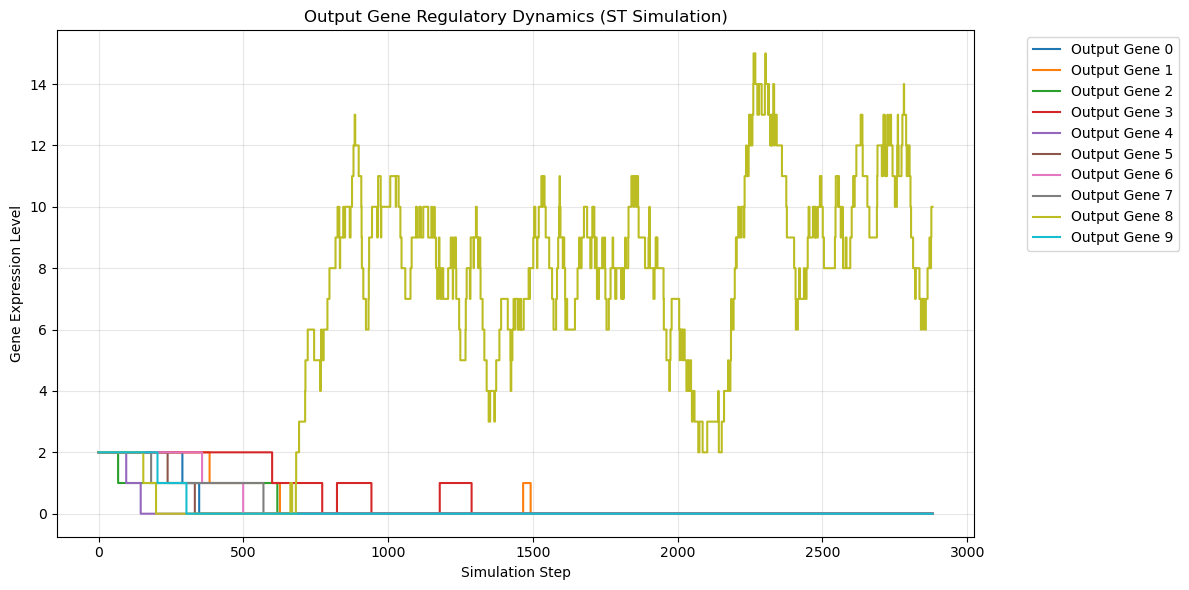

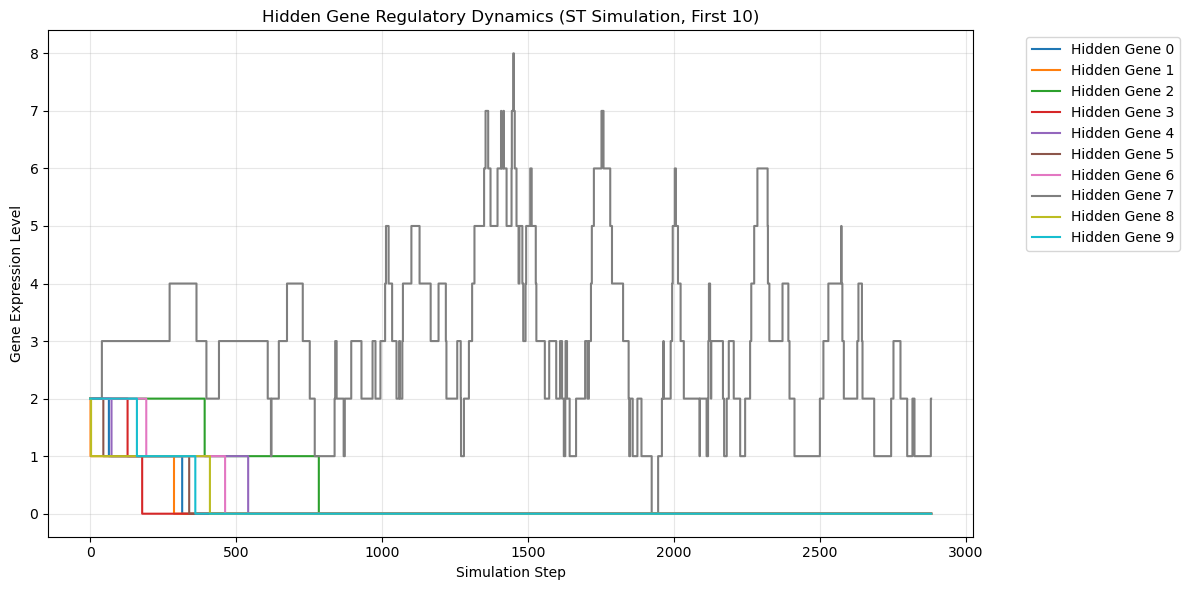

Final gene expression:
  Gene 0: 0.000
  Gene 1: 0.000
  Gene 2: 0.000
  Gene 3: 0.000
  Gene 4: 0.000
  Gene 5: 0.000
  Gene 6: 0.000
  Gene 7: 0.000
  Gene 8: 10.000
  Gene 9: 0.000

Predicted digit: 8

FINAL TEST ACCURACY: 0.9743 (97.43%)


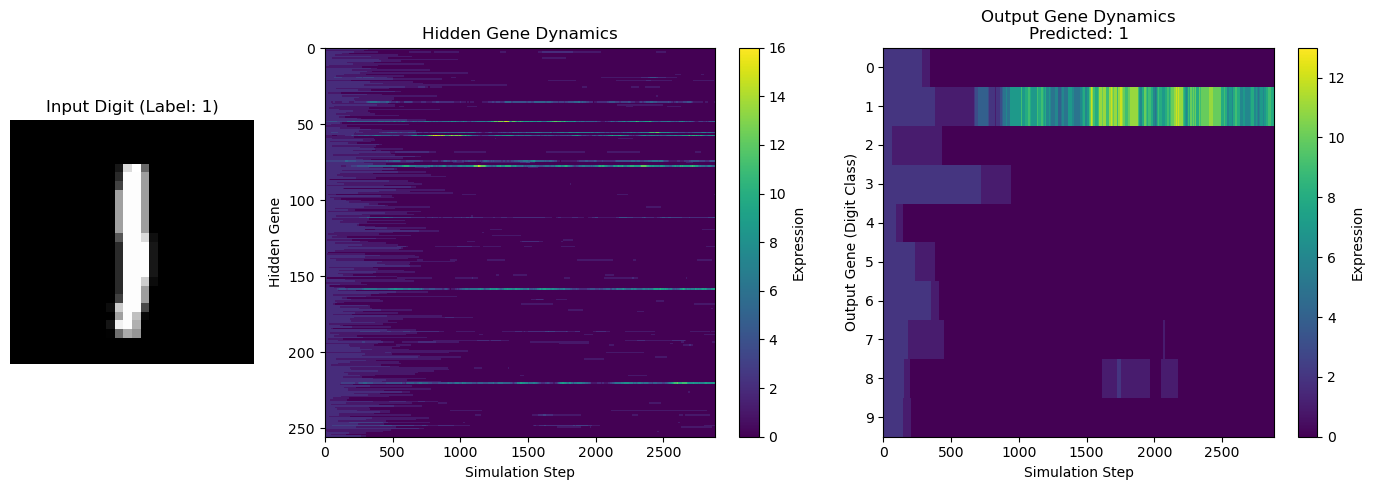

Plotting individual output gene traces (Gillespie-style)...


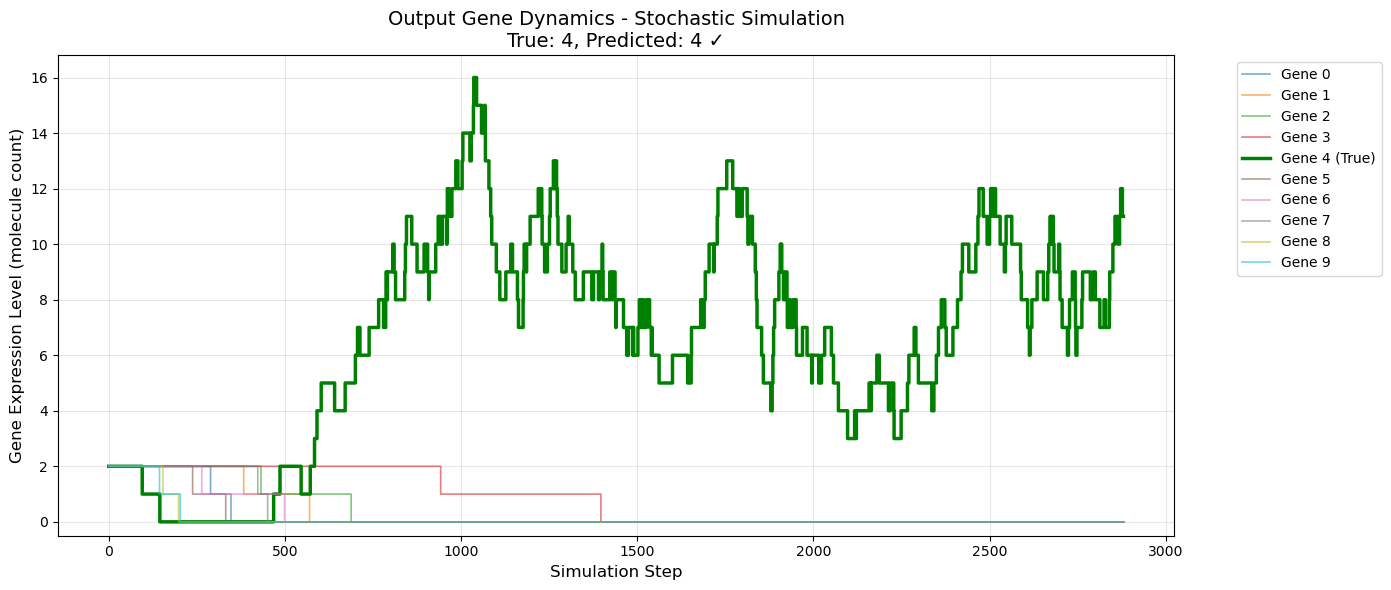

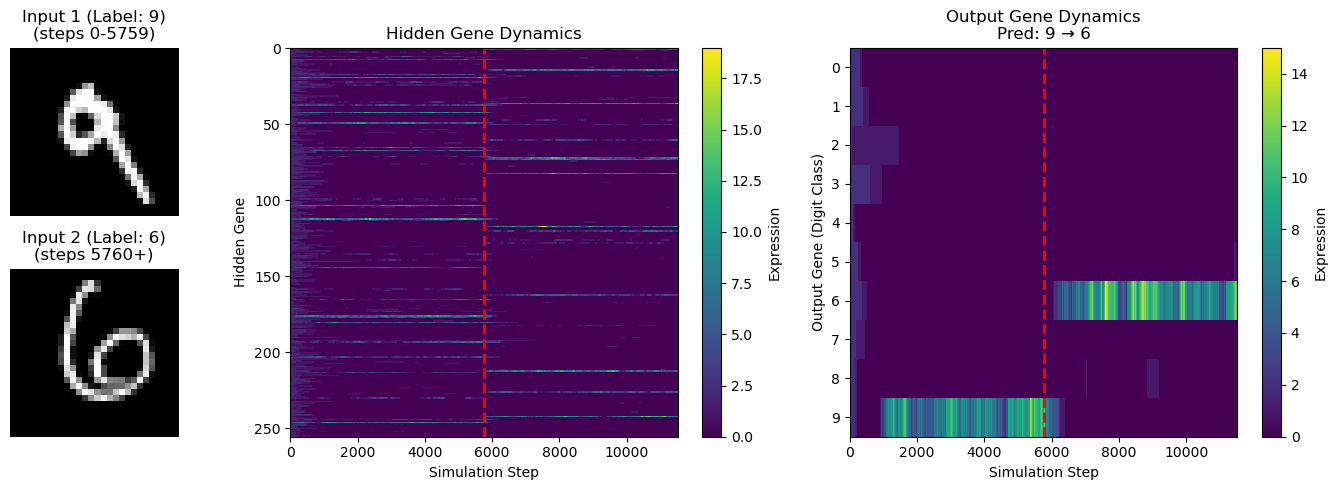

MC ACCURACY TESTS - ORIGINAL WEIGHTS
Active weights: original


MC(1) mean-prob accuracy: 0.9743000268936157


MC(3) mean-prob accuracy: 0.9782999753952026


MC(10) mean-prob accuracy: 0.9800000190734863

MC ACCURACY TESTS - AVERAGED WEIGHTS (SWA)
Active weights: averaged
MC(1) mean-prob accuracy: 0.9757999777793884
MC(3) mean-prob accuracy: 0.9800000190734863
MC(10) mean-prob accuracy: 0.980400025844574


In [ ]:
# =============================================================================
# =============================================================================
# PLOTTING AND ANALYSIS SECTION (runs after training/loading)
# =============================================================================
# =============================================================================

def plot_training_history(history, config):
    """Plot metrics"""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    epochs = range(1, len(history['train_loss']) + 1)

    axes[0].plot(epochs, history['train_loss'], 'b-', label='Train')
    axes[0].plot(epochs, history['test_loss'], 'r-', label='Test')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Loss')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Mark the legacy phase flag; it does not change the PST estimator.
    if config.st_switch_epoch < len(epochs):
        axes[0].axvline(x=config.st_switch_epoch + 0.5, color='gray', linestyle='--', label='Legacy phase flag (unused by PST)')

    axes[1].plot(epochs, history['train_acc'], 'b-', label='Train')
    axes[1].plot(epochs, history['test_acc'], 'r-', label='Test')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_title('Accuracy')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    if config.st_switch_epoch < len(epochs):
        axes[1].axvline(x=config.st_switch_epoch + 0.5, color='gray', linestyle='--', label='Legacy phase flag (unused by PST)')

    axes[2].plot(epochs, history['temperature'], 'g-')
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylabel('Legacy temperature')
    axes[2].set_title('Legacy schedule (unused by PST)')
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


def visualize_predictions(model, x_test, y_test, num_samples=10):
    """Show predictions (batched: one model call)."""
    indices = np.random.choice(len(x_test), num_samples, replace=False)

    # Batch all samples at once
    x_batch = tf.convert_to_tensor(x_test[indices], dtype=tf.float32)
    preds = model(x_batch, training=False).numpy()

    # True labels (handle one-hot or scalar)
    y_sel = y_test[indices]
    if np.ndim(y_sel) == 1:
        true_labels = y_sel.astype(int)
    else:
        true_labels = np.argmax(y_sel, axis=-1)

    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    axes = axes.flatten()

    for i, ax in enumerate(axes[:num_samples]):
        x_sample = x_batch[i].numpy()
        pred = preds[i]
        true_label = int(true_labels[i])
        pred_label = int(np.argmax(pred))

        ax.imshow(x_sample.reshape(28, 28), cmap='gray')
        ax.axis('off')

        color = 'green' if pred_label == true_label else 'red'
        ax.set_title(
            f'True: {true_label}, Pred: {pred_label}\nConf: {pred[pred_label]:.2f}',
            color=color
        )

    plt.tight_layout()
    plt.show()


def compute_gillespie_times(total_propensities):
    """
    Compute Gillespie waiting times from total propensities.
    
    In the Gillespie algorithm, the waiting time to the next reaction is
    exponentially distributed: tau ~ Exp(sum of propensities)
    
    Args:
        total_propensities: array of shape [num_steps] with total propensity at each step
        
    Returns:
        times: cumulative time array of shape [num_steps + 1] starting at 0
    """
    # Sample waiting times: tau = -ln(u) / total_propensity
    u = np.random.uniform(1e-10, 1.0, size=total_propensities.shape)
    waiting_times = -np.log(u) / np.maximum(total_propensities, 1e-10)
    
    # Cumulative time (prepend 0 for initial state)
    times = np.concatenate([[0.0], np.cumsum(waiting_times)])
    return times


def _compiled_rollout(model, tf_concentrations, num_steps):
    """
    Compiled rollout function for fast trajectory generation.
    
    Args:
        model: The GeneRegulatoryNetwork model
        tf_concentrations: Input tensor of shape [batch, 784]
        num_steps: Number of simulation steps
        
    Returns:
        out_traj: Output gene trajectories [num_steps+1, batch, num_genes]
        hid_traj: Hidden gene trajectories [num_steps+1, batch, num_hidden]
        prop_traj: Total propensities [num_steps, batch]
    """
    batch_size = tf.shape(tf_concentrations)[0]
    trans_input_hidden = tf.matmul(tf_concentrations, model.W_trans_hidden) + model.trans_bias_hidden
    temp = tf.constant(0.1, tf.float32)

    @tf.function
    def _rollout():
        hidden_state = tf.fill([batch_size, model.num_hidden_genes], tf.constant(2.0, tf.float32))
        output_state = tf.fill([batch_size, model.num_genes], tf.constant(2.0, tf.float32))

        out_ta = tf.TensorArray(tf.float32, size=num_steps + 1, clear_after_read=False)
        hid_ta = tf.TensorArray(tf.float32, size=num_steps + 1, clear_after_read=False)
        prop_ta = tf.TensorArray(tf.float32, size=num_steps, clear_after_read=False)

        out_ta = out_ta.write(0, output_state)
        hid_ta = hid_ta.write(0, hidden_state)

        def cond(i, h, o, out_ta, hid_ta, prop_ta):
            return i < num_steps

        def body(i, h, o, out_ta, hid_ta, prop_ta):
            props = model.compute_propensities(h, o, trans_input_hidden)
            total_prop = tf.reduce_sum(props, axis=-1)
            prop_ta = prop_ta.write(i, total_prop)

            log_props = tf.math.log(props)
            weights = stgs_estimator(log_props, temp, hard=True)
            h, o = model.apply_reaction(h, o, weights)

            out_ta = out_ta.write(i + 1, o)
            hid_ta = hid_ta.write(i + 1, h)
            return i + 1, h, o, out_ta, hid_ta, prop_ta

        _, _, _, out_ta, hid_ta, prop_ta = tf.while_loop(
            cond, body,
            loop_vars=[tf.constant(0), hidden_state, output_state, out_ta, hid_ta, prop_ta],
            parallel_iterations=1,
        )

        return out_ta.stack(), hid_ta.stack(), prop_ta.stack()

    return _rollout()


def _compiled_rollout_with_switch(model, tf_concentrations1, tf_concentrations2, num_steps, switch_step):
    """
    Compiled rollout function with input switching for fast trajectory generation.
    
    Args:
        model: The GeneRegulatoryNetwork model
        tf_concentrations1: First input tensor of shape [batch, 784]
        tf_concentrations2: Second input tensor of shape [batch, 784]
        num_steps: Number of simulation steps
        switch_step: Step at which to switch from input1 to input2
        
    Returns:
        out_traj: Output gene trajectories [num_steps+1, batch, num_genes]
        hid_traj: Hidden gene trajectories [num_steps+1, batch, num_hidden]
        prop_traj: Total propensities [num_steps, batch]
    """
    batch_size = tf.shape(tf_concentrations1)[0]
    trans_input_hidden1 = tf.matmul(tf_concentrations1, model.W_trans_hidden) + model.trans_bias_hidden
    trans_input_hidden2 = tf.matmul(tf_concentrations2, model.W_trans_hidden) + model.trans_bias_hidden
    temp = tf.constant(0.1, tf.float32)
    switch_step_tf = tf.constant(switch_step, tf.int32)

    @tf.function
    def _rollout():
        hidden_state = tf.fill([batch_size, model.num_hidden_genes], tf.constant(2.0, tf.float32))
        output_state = tf.fill([batch_size, model.num_genes], tf.constant(2.0, tf.float32))

        out_ta = tf.TensorArray(tf.float32, size=num_steps + 1, clear_after_read=False)
        hid_ta = tf.TensorArray(tf.float32, size=num_steps + 1, clear_after_read=False)
        prop_ta = tf.TensorArray(tf.float32, size=num_steps, clear_after_read=False)

        out_ta = out_ta.write(0, output_state)
        hid_ta = hid_ta.write(0, hidden_state)

        def cond(i, h, o, out_ta, hid_ta, prop_ta):
            return i < num_steps

        def body(i, h, o, out_ta, hid_ta, prop_ta):
            # Select input based on step
            trans_input_hidden = tf.cond(
                i < switch_step_tf,
                lambda: trans_input_hidden1,
                lambda: trans_input_hidden2
            )
            
            props = model.compute_propensities(h, o, trans_input_hidden)
            total_prop = tf.reduce_sum(props, axis=-1)
            prop_ta = prop_ta.write(i, total_prop)

            log_props = tf.math.log(props)
            weights = stgs_estimator(log_props, temp, hard=True)
            h, o = model.apply_reaction(h, o, weights)

            out_ta = out_ta.write(i + 1, o)
            hid_ta = hid_ta.write(i + 1, h)
            return i + 1, h, o, out_ta, hid_ta, prop_ta

        _, _, _, out_ta, hid_ta, prop_ta = tf.while_loop(
            cond, body,
            loop_vars=[tf.constant(0), hidden_state, output_state, out_ta, hid_ta, prop_ta],
            parallel_iterations=1,
        )

        return out_ta.stack(), hid_ta.stack(), prop_ta.stack()

    return _rollout()


def analyze_gene_dynamics(model, x_sample, num_steps=50, use_time=False):
    """
    Track gene expression over time with optional Gillespie time axis.
    
    Args:
        model: The GeneRegulatoryNetwork model
        x_sample: Input sample(s) of shape [batch, 784]
        num_steps: Number of simulation steps
        use_time: If True (default), use Gillespie time on x-axis. If False, use step number.
    """
    model.set_training_phase(use_st=True)
    tf_concentrations = tf.cast(x_sample, tf.float32)

    # Use compiled rollout
    out_traj_tf, hid_traj_tf, prop_traj_tf = _compiled_rollout(model, tf_concentrations, num_steps)

    # Convert once (no per-step sync)
    trajectories = out_traj_tf[:, 0, :].numpy()        # [T+1, 10]
    hidden_trajectories = hid_traj_tf[:, 0, :].numpy() # [T+1, H]
    total_propensities = prop_traj_tf[:, 0].numpy()    # [T]

    # Compute Gillespie times
    if use_time:
        times = compute_gillespie_times(total_propensities)
        x_label = 'Time (arbitrary units)'
    else:
        times = np.arange(num_steps + 1)
        x_label = 'Simulation Step'

    # Plot Output Genes
    plt.figure(figsize=(12, 6))
    for i in range(model.num_genes):
        plt.step(times, trajectories[:, i], where='post', label=f'Output Gene {i}', linewidth=1.5)
    plt.xlabel(x_label)
    plt.ylabel('Gene Expression Level')
    title = 'Output Gene Regulatory Dynamics (ST Simulation)'
    if use_time:
        title += f'\nTotal time: {times[-1]:.2f}'
    plt.title(title)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Plot Hidden Genes (first 10)
    plt.figure(figsize=(12, 6))
    for i in range(min(model.num_hidden_genes, 10)):
        plt.step(times, hidden_trajectories[:, i], where='post', label=f'Hidden Gene {i}', linewidth=1.5)
    plt.xlabel(x_label)
    plt.ylabel('Gene Expression Level')
    title = 'Hidden Gene Regulatory Dynamics (ST Simulation, First 10)'
    if use_time:
        title += f'\nTotal time: {times[-1]:.2f}'
    plt.title(title)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    print("\nFinal gene expression:")
    for i, expr in enumerate(trajectories[-1]):
        print(f"  Gene {i}: {expr:.3f}")
    print(f"\nPredicted digit: {int(np.argmax(trajectories[-1]))}")
    if use_time:
        print(f"Total simulation time: {times[-1]:.4f} (arbitrary units)")


def plot_gene_dynamics_heatmap(model, x_sample, y_true=None, num_steps=TLEN, use_time=False):
    """
    Plot digit alongside heatmaps of hidden and output gene dynamics.
    
    Args:
        model: The GeneRegulatoryNetwork model
        x_sample: Input sample of shape [1, 784]
        y_true: True label (one-hot or scalar)
        num_steps: Number of simulation steps
        use_time: If True (default), use Gillespie time on x-axis. If False, use step number.
    """
    model.set_training_phase(use_st=True)
    tf_concentrations = tf.cast(x_sample, tf.float32)

    # Use compiled rollout
    out_traj_tf, hid_traj_tf, prop_traj_tf = _compiled_rollout(model, tf_concentrations, num_steps)

    # Convert once
    hidden_trajectories = hid_traj_tf[:, 0, :].numpy()
    output_trajectories = out_traj_tf[:, 0, :].numpy()
    total_propensities = prop_traj_tf[:, 0].numpy()

    # Compute Gillespie times
    if use_time:
        times = compute_gillespie_times(total_propensities)
        x_label = 'Time (a.u.)'
    else:
        times = np.arange(num_steps + 1)
        x_label = 'Simulation Step'

    # Create figure
    fig, axes = plt.subplots(1, 3, figsize=(14, 5), gridspec_kw={'width_ratios': [0.5, 1, 1]})

    # Left: Digit image
    axes[0].imshow(x_sample.reshape(28, 28), cmap='gray')
    title = 'Input Digit'
    if y_true is not None:
        title += f' (Label: {np.argmax(y_true)})'
    axes[0].set_title(title)
    axes[0].axis('off')

    # Center: Hidden gene dynamics heatmap
    # For heatmaps with non-uniform time, we use extent to map to time axis
    if use_time:
        extent_h = [times[0], times[-1], model.num_hidden_genes - 0.5, -0.5]
        extent_o = [times[0], times[-1], model.num_genes - 0.5, -0.5]
    else:
        extent_h = [0, num_steps, model.num_hidden_genes - 0.5, -0.5]
        extent_o = [0, num_steps, model.num_genes - 0.5, -0.5]
    
    im1 = axes[1].imshow(hidden_trajectories.T, aspect='auto', cmap='viridis', 
                          interpolation='nearest', extent=extent_h)
    axes[1].set_xlabel(x_label)
    axes[1].set_ylabel('Hidden Gene')
    axes[1].set_title('Hidden Gene Dynamics')
    plt.colorbar(im1, ax=axes[1], label='Expression')

    # Right: Output gene dynamics heatmap
    im2 = axes[2].imshow(output_trajectories.T, aspect='auto', cmap='viridis', 
                          interpolation='nearest', extent=extent_o)
    axes[2].set_xlabel(x_label)
    axes[2].set_ylabel('Output Gene (Digit Class)')
    pred_title = f'Output Gene Dynamics\nPredicted: {np.argmax(output_trajectories[-1])}'
    if use_time:
        pred_title += f' | T={times[-1]:.1f}'
    axes[2].set_title(pred_title)
    axes[2].set_yticks(range(10))
    plt.colorbar(im2, ax=axes[2], label='Expression')

    plt.tight_layout()
    plt.show()


def plot_gene_dynamics_heatmap_switch(model, x_sample1, x_sample2=None, y_true1=None, y_true2=None,
                                       num_steps=TLEN, switch_step=None, use_time=False):
    """
    Plot digit alongside heatmaps of hidden and output gene dynamics, with optional input switch.
    
    Args:
        model: The GeneRegulatoryNetwork model
        x_sample1: First input sample of shape [1, 784]
        x_sample2: Second input sample (optional, defaults to x_sample1)
        y_true1: True label for first sample
        y_true2: True label for second sample
        num_steps: Number of simulation steps
        switch_step: Step at which to switch inputs (default: num_steps // 2)
        use_time: If True (default), use Gillespie time on x-axis. If False, use step number.
    """
    from matplotlib.gridspec import GridSpec

    # If no second sample, just use the first throughout
    if x_sample2 is None:
        x_sample2 = x_sample1
        y_true2 = y_true1

    if switch_step is None:
        switch_step = num_steps // 2

    model.set_training_phase(use_st=True)
    tf_concentrations1 = tf.cast(x_sample1, tf.float32)
    tf_concentrations2 = tf.cast(x_sample2, tf.float32)

    # Use compiled rollout with switch
    out_traj_tf, hid_traj_tf, prop_traj_tf = _compiled_rollout_with_switch(
        model, tf_concentrations1, tf_concentrations2, num_steps, switch_step
    )

    # Convert once
    hidden_trajectories = hid_traj_tf[:, 0, :].numpy()
    output_trajectories = out_traj_tf[:, 0, :].numpy()
    total_propensities = prop_traj_tf[:, 0].numpy()

    # Compute Gillespie times
    if use_time:
        times = compute_gillespie_times(total_propensities)
        x_label = 'Time (a.u.)'
        
        switch_x = times[0] + (times[-1] - times[0]) * switch_step / num_steps
    else:
        times = np.arange(num_steps + 1)
        x_label = 'Simulation Step'
        switch_x = switch_step

    # Create figure
    fig = plt.figure(figsize=(14, 5))
    gs = GridSpec(2, 3, width_ratios=[0.5, 1, 1], height_ratios=[1, 1])

    # Top-left: First digit
    ax0a = fig.add_subplot(gs[0, 0])
    ax0a.imshow(x_sample1.reshape(28, 28), cmap='gray', interpolation='nearest')
    label1 = f' (Label: {np.argmax(y_true1)})' if y_true1 is not None else ''
    if use_time:
        ax0a.set_title(f'Input 1{label1}\n(t < {switch_x:.1f})')
    else:
        ax0a.set_title(f'Input 1{label1}\n(steps 0-{switch_step - 1})')
    ax0a.axis('off')

    # Bottom-left: Second digit
    ax0b = fig.add_subplot(gs[1, 0])
    ax0b.imshow(x_sample2.reshape(28, 28), cmap='gray', interpolation='nearest')
    label2 = f' (Label: {np.argmax(y_true2)})' if y_true2 is not None else ''
    if use_time:
        ax0b.set_title(f'Input 2{label2}\n(t ≥ {switch_x:.1f})')
    else:
        ax0b.set_title(f'Input 2{label2}\n(steps {switch_step}+)')
    ax0b.axis('off')

    # Compute extent for heatmaps
    if use_time:
        extent_h = [times[0], times[-1], model.num_hidden_genes - 0.5, -0.5]
        extent_o = [times[0], times[-1], model.num_genes - 0.5, -0.5]
    else:
        extent_h = [0, num_steps, model.num_hidden_genes - 0.5, -0.5]
        extent_o = [0, num_steps, model.num_genes - 0.5, -0.5]

    # Center: Hidden gene dynamics heatmap
    ax1 = fig.add_subplot(gs[:, 1])
    im1 = ax1.imshow(hidden_trajectories.T, aspect='auto', cmap='viridis', 
                      interpolation='nearest', extent=extent_h)
    ax1.axvline(x=switch_x, color='red', linestyle='--', linewidth=2)
    ax1.set_xlabel(x_label)
    ax1.set_ylabel('Hidden Gene')
    ax1.set_title('Hidden Gene Dynamics')
    plt.colorbar(im1, ax=ax1, label='Expression')

    # Right: Output gene dynamics heatmap
    ax2 = fig.add_subplot(gs[:, 2])
    im2 = ax2.imshow(output_trajectories.T, aspect='auto', cmap='viridis', 
                      interpolation='nearest', extent=extent_o)
    ax2.axvline(x=switch_x, color='red', linestyle='--', linewidth=2)
    ax2.set_xlabel(x_label)
    ax2.set_ylabel('Output Gene (Digit Class)')
    pred_before = np.argmax(output_trajectories[switch_step])
    pred_after = np.argmax(output_trajectories[-1])
    ax2.set_title(f'Output Gene Dynamics\nPred: {pred_before} → {pred_after}')
    ax2.set_yticks(range(10))
    plt.colorbar(im2, ax=ax2, label='Expression')

    plt.tight_layout()
    plt.show()


def plot_output_gene_traces(model, x_sample, y_true=None, num_steps=TLEN, use_time=False, 
                            genes_to_plot=None, figsize=(14, 6)):
    """
    Plot individual output gene traces as step functions (Gillespie-style).
    
    The curves show discrete stochastic jumps in gene expression.
    
    Args:
        model: The GeneRegulatoryNetwork model
        x_sample: Input sample of shape [1, 784]
        y_true: True label (one-hot or scalar)
        num_steps: Number of simulation steps
        use_time: If True (default), use Gillespie time on x-axis. If False, use step number.
        genes_to_plot: List of gene indices to plot (default: all 10 output genes)
        figsize: Figure size tuple
    """
    model.set_training_phase(use_st=True)
    tf_concentrations = tf.cast(x_sample, tf.float32)

    # Use compiled rollout
    out_traj_tf, _, prop_traj_tf = _compiled_rollout(model, tf_concentrations, num_steps)

    # Convert once
    output_trajectories = out_traj_tf[:, 0, :].numpy()
    total_propensities = prop_traj_tf[:, 0].numpy()

    # Compute Gillespie times
    if use_time:
        times = compute_gillespie_times(total_propensities)
        x_label = 'Time (arbitrary units)'
    else:
        times = np.arange(num_steps + 1)
        x_label = 'Simulation Step'

    # Determine which genes to plot
    if genes_to_plot is None:
        genes_to_plot = list(range(model.num_genes))
    
    # Get true and predicted labels
    if y_true is not None:
        true_label = int(np.argmax(y_true))
    else:
        true_label = None
    pred_label = int(np.argmax(output_trajectories[-1]))

    # Create color map - highlight true label in green, predicted in blue (if different)
    colors = plt.cm.tab10(np.linspace(0, 1, 10))
    
    fig, ax = plt.subplots(figsize=figsize)
    
    for i in genes_to_plot:
        # Determine line style and color
        if true_label is not None and i == true_label:
            color = 'green'
            linewidth = 2.5
            alpha = 1.0
            label = f'Gene {i} (True)'
        elif i == pred_label and pred_label != true_label:
            color = 'red'
            linewidth = 2.5
            alpha = 1.0
            label = f'Gene {i} (Pred)'
        elif i == pred_label:
            color = 'green'
            linewidth = 2.5
            alpha = 1.0
            label = f'Gene {i} (True=Pred)'
        else:
            color = colors[i]
            linewidth = 1.2
            alpha = 0.6
            label = f'Gene {i}'
        
        ax.step(times, output_trajectories[:, i], where='post', 
                color=color, linewidth=linewidth, alpha=alpha, label=label)

    ax.set_xlabel(x_label, fontsize=12)
    ax.set_ylabel('Gene Expression Level (molecule count)', fontsize=12)
    
    title = 'Output Gene Dynamics - Stochastic Simulation'
    if true_label is not None:
        title += f'\nTrue: {true_label}, Predicted: {pred_label}'
        if true_label == pred_label:
            title += ' ✓'
        else:
            title += ' ✗'
    if use_time:
        title += f' | Total time: {times[-1]:.2f}'
    ax.set_title(title, fontsize=14)
    
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(bottom=-0.5)
    
    plt.tight_layout()
    plt.show()
    
    return times, output_trajectories


@tf.function
def mc_mean_accuracy_large_batch(model, x_test, y_test, mc=5):
    """
    Evaluates accuracy using mean probabilities over 'mc' stochastic realizations,
    by concatenating 'mc' copies of the full test set into one large batch.
    Assumes x_test is [N,784], y_test is one-hot [N,10].
    """
    x_test = tf.cast(x_test, tf.float32)
    y_test = tf.cast(y_test, tf.float32)

    n = tf.shape(x_test)[0]

    # Concatenate mc copies: [mc*N, 784]
    x_big = tf.tile(x_test, multiples=[mc, 1])

    # One stochastic forward pass over the large batch: [mc*N, 10]
    p_big = model(x_big, training=False)

    # Reshape to [mc, N, 10] then average over mc -> [N,10]
    p = tf.reshape(p_big, [mc, n, tf.shape(p_big)[-1]])
    p_mean = tf.reduce_mean(p, axis=0)

    y_true = tf.argmax(y_test, axis=-1)
    y_pred = tf.argmax(p_mean, axis=-1)

    acc = tf.reduce_mean(tf.cast(tf.equal(y_true, y_pred), tf.float32))
    return acc



@tf.function
def mc_timeavg_accuracy_large_batch(
    model,
    x_test,
    y_test,
    mc=5,
    final_frac=0.25,
    average_probabilities=False,
):
    """
    MC evaluation in one big batch (mc * N), but predictions are computed from
    a time-average over the final fraction of simulation steps.
    
    Dynamic Tensor inputs for `mc` and `final_frac` avoid tf.function
    retracing while allowing random-number states to advance between calls.
    """
    x_test = tf.cast(x_test, tf.float32)
    y_test = tf.cast(y_test, tf.float32)

    N = tf.shape(x_test)[0]
    T = tf.constant(model.num_steps, tf.int32)

    # Build big batch: [mc*N, 784] using tf.stack for dynamic tensor shapes
    x_big = tf.tile(x_test, multiples=tf.stack([mc, 1]))

    # Hoist loop-invariant hidden transcription input: [mc*N, H]
    trans_input_hidden = tf.matmul(x_big, model.W_trans_hidden) + model.trans_bias_hidden

    # Initial states
    bsz = tf.shape(x_big)[0]
    h = tf.fill([bsz, model.num_hidden_genes], tf.constant(2.0, tf.float32))
    o = tf.fill([bsz, model.num_genes], tf.constant(2.0, tf.float32))

    # Inference-like settings
    temp = tf.constant(0.1, tf.float32)

    # Average over last final_frac of steps
    start = tf.cast(
        tf.floor(tf.cast(T, tf.float32) * (1.0 - tf.cast(final_frac, tf.float32))),
        tf.int32,
    )

    accum = tf.zeros([bsz, model.num_genes], tf.float32)
    count = tf.constant(0, tf.int32)

    def cond(i, h, o, accum, count):
        return i < T

    def body(i, h, o, accum, count):
        props = model.compute_propensities(h, o, trans_input_hidden)
        log_props = tf.math.log(props)

        # Force ST sampling (hard=True) for testing
        w = stgs_estimator(log_props, temp, hard=True)

        h, o = model.apply_reaction(h, o, w)

        def add():
            if average_probabilities:
                return accum + tf.nn.softmax(o, axis=-1), count + 1
            else:
                return accum + o, count + 1

        accum, count = tf.cond(i >= start, add, lambda: (accum, count))
        return i + 1, h, o, accum, count

    _, _, _, accum, count = tf.while_loop(
        cond,
        body,
        loop_vars=[tf.constant(0, tf.int32), h, o, accum, count],
        parallel_iterations=1,
    )

    count_f = tf.cast(tf.maximum(count, 1), tf.float32)
    avg_over_time = accum / count_f

    # Convert to probabilities if we averaged gene counts
    if average_probabilities:
        p_time = avg_over_time
    else:
        p_time = tf.nn.softmax(avg_over_time, axis=-1)

    # Reshape to [mc, N, 10], then average over MC using tf.stack
    p_mc = tf.reshape(p_time, tf.stack([mc, N, model.num_genes]))
    p_mean = tf.reduce_mean(p_mc, axis=0)

    y_true = tf.argmax(y_test, axis=-1)
    y_pred = tf.argmax(p_mean, axis=-1)

    return tf.reduce_mean(tf.cast(tf.equal(y_true, y_pred), tf.float32))

# =============================================================================
# RUN PLOTTING AND ANALYSIS (only if in main)
# =============================================================================

if __name__ == "__main__":
    # =========================================================================
    # PLOTTING SECTION (runs in both modes after training/loading)
    # =========================================================================
    print("\n[5/5] Visualizing..." if TRAIN_MODE else "\n[2/2] Visualizing...")
    
    # Plot with original weights (default)
    print(f"\n--- Using {model.get_active_weights_type()} weights ---")
    plot_training_history(history, config)
    

    # Analyze dynamics
    print("\nAnalyzing gene dynamics...")
    sample_idx = np.random.randint(len(x_test))
    analyze_gene_dynamics(model, x_test[sample_idx:sample_idx + 1], num_steps=TLEN)

    final_acc = history['test_acc'][-1]
    print(f"\n{'=' * 80}")
    print(f"FINAL TEST ACCURACY: {final_acc:.4f} ({final_acc * 100:.2f}%)")
    print(f"{'=' * 80}")

    # Heatmap visualization
    sample_idx = np.random.randint(len(x_test))
    plot_gene_dynamics_heatmap(model, x_test[sample_idx:sample_idx + 1], y_test[sample_idx])
    
    # Publication-quality step plot of output gene traces
    print("\nPlotting individual output gene traces (Gillespie-style)...")
    sample_idx = np.random.randint(len(x_test))
    plot_output_gene_traces(model, x_test[sample_idx:sample_idx + 1], y_test[sample_idx], num_steps=TLEN)

    # Two digits with switch
    idx1, idx2 = 7, 100
    plot_gene_dynamics_heatmap_switch(
        model,
        x_test[idx1:idx1 + 1], x_test[idx2:idx2 + 1],
        y_test[idx1], y_test[idx2],
        num_steps=2 * TLEN * 2,
        switch_step=2 * TLEN
    )

    # ==========================================================================
    # MC ACCURACY TESTS WITH ORIGINAL WEIGHTS
    # ==========================================================================
    print("\n" + "=" * 80)
    print("MC ACCURACY TESTS - ORIGINAL WEIGHTS")
    print("=" * 80)
    
    model.use_original_weights()
    print(f"Active weights: {model.get_active_weights_type()}")
    
    acc_mc1 = mc_mean_accuracy_large_batch(model, x_test, y_test, mc=1)
    print("MC(1) mean-prob accuracy:", float(acc_mc1.numpy()))
    acc_mc3 = mc_mean_accuracy_large_batch(model, x_test, y_test, mc=3)
    print("MC(3) mean-prob accuracy:", float(acc_mc3.numpy()))
    acc_mc10 = mc_mean_accuracy_large_batch(model, x_test, y_test, mc=10)
    print("MC(10) mean-prob accuracy:", float(acc_mc10.numpy()))
    
    

    
    
    
    
    
    
    
    
    

    # ==========================================================================
    # MC ACCURACY TESTS WITH AVERAGED WEIGHTS
    # ==========================================================================
    if model.has_averaged_weights():
        print("\n" + "=" * 80)
        print("MC ACCURACY TESTS - AVERAGED WEIGHTS (SWA)")
        print("=" * 80)
        
        model.use_averaged_weights()
        print(f"Active weights: {model.get_active_weights_type()}")
        
        acc_mc1 = mc_mean_accuracy_large_batch(model, x_test, y_test, mc=1)
        print("MC(1) mean-prob accuracy:", float(acc_mc1.numpy()))
        acc_mc3 = mc_mean_accuracy_large_batch(model, x_test, y_test, mc=3)
        print("MC(3) mean-prob accuracy:", float(acc_mc3.numpy()))
        acc_mc10 = mc_mean_accuracy_large_batch(model, x_test, y_test, mc=10)
        print("MC(10) mean-prob accuracy:", float(acc_mc10.numpy()))
        
        

        
        
        
        
        
        
        
        
        
        
        
        
        


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

# =============================================================================
# PLOT STYLE
# =============================================================================
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ["Helvetica", "Arial", "DejaVu Sans"],
    'font.size': 11,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'legend.fontsize': 10,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'lines.linewidth': 1.5,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.autolayout': False,
})

def _panel_label(ax, label):
    ax.text(-0.15, 1.05, label, transform=ax.transAxes,
            ha="left", va="bottom", fontsize=15, fontweight="bold")

def plot_training_history_stylized(history, config, filename_prefix='Training_History2'):
    """
    Plot loss, accuracy, and the recorded legacy temperature schedule.
    The legacy schedule is inactive in PST training.
    """
    
    # Set up the three-panel layout.
    fig = plt.figure(figsize=(12, 3.0))
    gs = gridspec.GridSpec(1, 3, wspace=0.3)
    
    epochs = range(1, len(history['train_loss']) + 1)
    
    # Matplotlib tab10 colors.
    c_train = 'tab:blue'    # Matches "Run" / "Learned"
    c_test = 'tab:red'   # Matches secondary plots
    c_temp = 'tab:green'    # Distinct for temp
    c_switch = 'k'          # Black for structural lines (like "True Value")
    
    # =========================================================================
    # Panel A: Loss
    # =========================================================================
    ax = fig.add_subplot(gs[0])
    # Training and test history curves.
    ax.plot(epochs, history['train_loss'], '.-', drawstyle='steps-post', color=c_train, alpha=0.9, label='Train')
    ax.plot(epochs, history['test_loss'], '.-', drawstyle='steps-post', color=c_test, alpha=0.9, label='Test')
    
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.set_title('Loss Convergence')
    
    # Mark the legacy phase flag; it does not change the PST estimator.
    if hasattr(config, 'st_switch_epoch') and config.st_switch_epoch < len(epochs):
        ax.axvline(x=config.st_switch_epoch + 1, color=c_switch, 
                   linestyle='--', alpha=0.6, label='Legacy phase flag (unused by PST)', zorder=0)
                   
    ax.legend(frameon=False)
    ax.grid(True, alpha=0.2)
    _panel_label(ax, "B")

    # =========================================================================
    # Panel B: Accuracy
    # =========================================================================
    ax = fig.add_subplot(gs[1])
    ax.plot(epochs, history['train_acc'], '.-', drawstyle='steps-post', color=c_train, alpha=0.9, label='Train')
    ax.plot(epochs, history['test_acc'], '.-', drawstyle='steps-post', color=c_test, alpha=0.9, label='Test')

    ax.set_ylim(0.9, 1.01) # Slight padding at top
    
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Accuracy')
    ax.set_title('Accuracy')
    
    if hasattr(config, 'st_switch_epoch') and config.st_switch_epoch < len(epochs):
        ax.axvline(x=config.st_switch_epoch + 1, color=c_switch, 
                   linestyle='--', alpha=0.6, zorder=0)
    
    # The train/test legend is shared across panels.
    
    ax.grid(True, alpha=0.2)
    _panel_label(ax, "C")

    # =========================================================================
    # Panel C: Temperature
    # =========================================================================
    ax = fig.add_subplot(gs[2])
    ax.plot(epochs, history['temperature'], '.-', drawstyle='steps-post', color=c_temp, alpha=0.9)
    
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Legacy temperature')
    ax.set_title('Legacy schedule (unused by PST)')
    ax.grid(True, alpha=0.2)
    
    if hasattr(config, 'st_switch_epoch') and config.st_switch_epoch < len(epochs):
         ax.axvline(x=config.st_switch_epoch + 1, color=c_switch, 
                   linestyle='--', alpha=0.6, zorder=0)

    _panel_label(ax, "D")

    # =========================================================================
    # Saving
    # =========================================================================
    print(f"Saving {filename_prefix}...")
    for ext in ['.pdf', '.svg', '.png']:
        plt.savefig(f'{filename_prefix}{ext}', transparent=True, bbox_inches='tight', dpi=300)
    
    plt.show()

# Example Usage:
plot_training_history_stylized(history, config)

Saving Training_History2...


In [ ]:
def _compiled_rollout_with_two_switches(model, tf_concentrations1, tf_concentrations2, tf_concentrations3,
                                         num_steps, switch_step1, switch_step2):
    """
    Compiled rollout function with two input switches for fast trajectory generation.
    
    Args:
        model: The GeneRegulatoryNetwork model
        tf_concentrations1: First input tensor of shape [batch, 784]
        tf_concentrations2: Second input tensor of shape [batch, 784]
        tf_concentrations3: Third input tensor of shape [batch, 784]
        num_steps: Number of simulation steps
        switch_step1: Step at which to switch from input1 to input2
        switch_step2: Step at which to switch from input2 to input3
        
    Returns:
        out_traj: Output gene trajectories [num_steps+1, batch, num_genes]
        hid_traj: Hidden gene trajectories [num_steps+1, batch, num_hidden]
        prop_traj: Total propensities [num_steps, batch]
    """
    batch_size = tf.shape(tf_concentrations1)[0]
    trans_input_hidden1 = tf.matmul(tf_concentrations1, model.W_trans_hidden) + model.trans_bias_hidden
    trans_input_hidden2 = tf.matmul(tf_concentrations2, model.W_trans_hidden) + model.trans_bias_hidden
    trans_input_hidden3 = tf.matmul(tf_concentrations3, model.W_trans_hidden) + model.trans_bias_hidden
    temp = tf.constant(0.1, tf.float32)
    switch_step1_tf = tf.constant(switch_step1, tf.int32)
    switch_step2_tf = tf.constant(switch_step2, tf.int32)

    @tf.function
    def _rollout():
        hidden_state = tf.fill([batch_size, model.num_hidden_genes], tf.constant(2.0, tf.float32))
        output_state = tf.fill([batch_size, model.num_genes], tf.constant(2.0, tf.float32))

        out_ta = tf.TensorArray(tf.float32, size=num_steps + 1, clear_after_read=False)
        hid_ta = tf.TensorArray(tf.float32, size=num_steps + 1, clear_after_read=False)
        prop_ta = tf.TensorArray(tf.float32, size=num_steps, clear_after_read=False)

        out_ta = out_ta.write(0, output_state)
        hid_ta = hid_ta.write(0, hidden_state)

        def cond(i, h, o, out_ta, hid_ta, prop_ta):
            return i < num_steps

        def body(i, h, o, out_ta, hid_ta, prop_ta):
            # Select input based on step (nested tf.cond for three regions)
            trans_input_hidden = tf.cond(
                i < switch_step1_tf,
                lambda: trans_input_hidden1,
                lambda: tf.cond(
                    i < switch_step2_tf,
                    lambda: trans_input_hidden2,
                    lambda: trans_input_hidden3
                )
            )
            
            props = model.compute_propensities(h, o, trans_input_hidden)
            total_prop = tf.reduce_sum(props, axis=-1)
            prop_ta = prop_ta.write(i, total_prop)

            log_props = tf.math.log(props)
            weights = stgs_estimator(log_props, temp, hard=True)
            h, o = model.apply_reaction(h, o, weights)

            out_ta = out_ta.write(i + 1, o)
            hid_ta = hid_ta.write(i + 1, h)
            return i + 1, h, o, out_ta, hid_ta, prop_ta

        _, _, _, out_ta, hid_ta, prop_ta = tf.while_loop(
            cond, body,
            loop_vars=[tf.constant(0), hidden_state, output_state, out_ta, hid_ta, prop_ta],
            parallel_iterations=1,
        )

        return out_ta.stack(), hid_ta.stack(), prop_ta.stack()

    return _rollout()


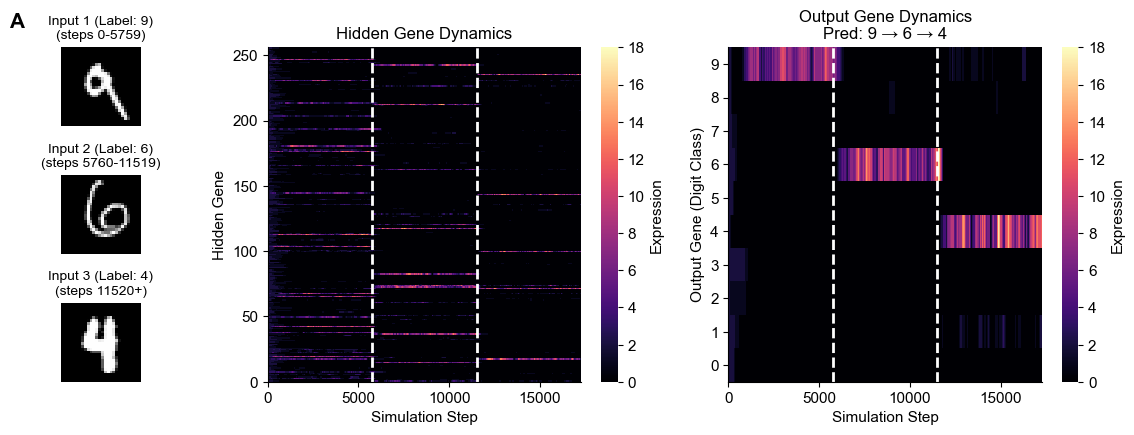

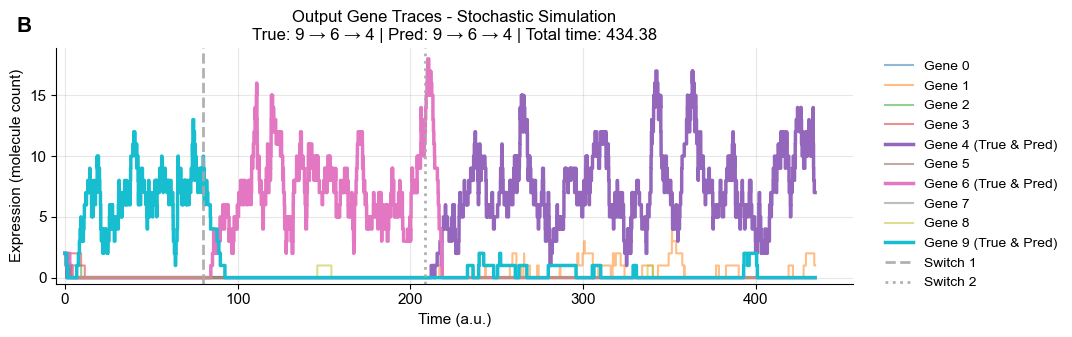

In [ ]:
from matplotlib.gridspec import GridSpec

# =============================================================================
# STYLE CONFIGURATION (Global)
# =============================================================================
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ["Helvetica", "Arial", "DejaVu Sans"],
    'font.size': 11,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'legend.fontsize': 10,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'lines.linewidth': 1.5,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.autolayout': False,
    'pdf.fonttype': 42, # Editable text
    'ps.fonttype': 42,
})

def _panel_label(ax, label):
    ax.text(-0.05, 1.05, label, transform=ax.transAxes,
            ha="left", va="bottom", fontsize=15, fontweight="bold")

def _panel_labelL(ax, label):
    ax.text(-0.45-0.2, 1.15+0.05, label, transform=ax.transAxes,
            ha="left", va="bottom", fontsize=15, fontweight="bold")

def plot_gene_dynamics_heatmap_three_digits(model, x_sample1, x_sample2, x_sample3,
                                             y_true1=None, y_true2=None, y_true3=None,
                                             num_steps=TLEN, switch_step1=None, switch_step2=None,
                                             use_time=True, genes_to_plot=None):

    if switch_step1 is None:
        switch_step1 = num_steps // 3
    if switch_step2 is None:
        switch_step2 = 2 * num_steps // 3

    model.set_training_phase(use_st=True)
    tf_concentrations1 = tf.cast(x_sample1, tf.float32)
    tf_concentrations2 = tf.cast(x_sample2, tf.float32)
    tf_concentrations3 = tf.cast(x_sample3, tf.float32)

    # Use compiled rollout with two switches
    out_traj_tf, hid_traj_tf, prop_traj_tf = _compiled_rollout_with_two_switches(
        model, tf_concentrations1, tf_concentrations2, tf_concentrations3,
        num_steps, switch_step1, switch_step2
    )

    # Convert once
    hidden_trajectories = hid_traj_tf[:, 0, :].numpy()  # [T+1, H]
    output_trajectories = out_traj_tf[:, 0, :].numpy()  # [T+1, 10]
    total_propensities = prop_traj_tf[:, 0].numpy()     # [T]

    # Compute Gillespie times
    if use_time:
        times = compute_gillespie_times(total_propensities)  # [T+1]
        x_label = 'Time (a.u.)'
        switch_x1 = times[switch_step1]
        switch_x2 = times[switch_step2]
    else:
        times = np.arange(num_steps + 1, dtype=float)
        x_label = 'Simulation Step'
        switch_x1 = float(switch_step1)
        switch_x2 = float(switch_step2)

    # Create mesh grids for pcolormesh
    time_edges = np.zeros(len(times) + 1)
    time_edges[0] = times[0]
    time_edges[1:-1] = (times[:-1] + times[1:]) / 2
    time_edges[-1] = times[-1]

    hidden_gene_edges = np.arange(model.num_hidden_genes + 1)
    output_gene_edges = np.arange(model.num_genes + 1)

    # Get predictions at each stage
    pred1 = np.argmax(output_trajectories[switch_step1]+0.1*np.mean(output_trajectories[switch_step1-100:switch_step1],axis=0))
    pred2 = np.argmax(output_trajectories[switch_step2]+0.1*np.mean(output_trajectories[switch_step2-100:switch_step2],axis=0))
    pred3 = np.argmax(output_trajectories[-1]+0.1*np.mean(output_trajectories[-100:],axis=0))

    # Get true labels
    true1 = int(np.argmax(y_true1)) if y_true1 is not None else None
    true2 = int(np.argmax(y_true2)) if y_true2 is not None else None
    true3 = int(np.argmax(y_true3)) if y_true3 is not None else None

    # =========================================================================
    # FIGURE 1: Heatmaps
    # =========================================================================
    fig = plt.figure(figsize=(12, 4.5))
    gs = GridSpec(3, 3, width_ratios=[0.5, 1, 1], height_ratios=[1, 1, 1])

    # Top-left: First digit
    ax0a = fig.add_subplot(gs[0, 0])
    ax0a.imshow(x_sample1.reshape(28, 28), cmap='gray', interpolation='nearest')
    label1 = f' (Label: {true1})' if true1 is not None else ''
    if use_time:
        ax0a.set_title(f'Input 1{label1}\n(t < {switch_x1:.1f})', fontsize=10)
    else:
        ax0a.set_title(f'Input 1{label1}\n(steps 0-{switch_step1 - 1})', fontsize=10)
    ax0a.axis('off')
    _panel_labelL(ax0a, "A")

    # Middle-left: Second digit
    ax0b = fig.add_subplot(gs[1, 0])
    ax0b.imshow(x_sample2.reshape(28, 28), cmap='gray', interpolation='nearest')
    label2 = f' (Label: {true2})' if true2 is not None else ''
    if use_time:
        ax0b.set_title(f'Input 2{label2}\n({switch_x1:.1f} ≤ t < {switch_x2:.1f})', fontsize=10)
    else:
        ax0b.set_title(f'Input 2{label2}\n(steps {switch_step1}-{switch_step2 - 1})', fontsize=10)
    ax0b.axis('off')

    # Bottom-left: Third digit
    ax0c = fig.add_subplot(gs[2, 0])
    ax0c.imshow(x_sample3.reshape(28, 28), cmap='gray', interpolation='nearest')
    label3 = f' (Label: {true3})' if true3 is not None else ''
    if use_time:
        ax0c.set_title(f'Input 3{label3}\n(t ≥ {switch_x2:.1f})', fontsize=10)
    else:
        ax0c.set_title(f'Input 3{label3}\n(steps {switch_step2}+)', fontsize=10)
    ax0c.axis('off')

    # Center: Hidden gene dynamics heatmap with pcolormesh
    ax1 = fig.add_subplot(gs[:, 1])
    X_h, Y_h = np.meshgrid(time_edges, hidden_gene_edges)
    im1 = ax1.pcolormesh(X_h, Y_h, hidden_trajectories.T, cmap='magma', shading='flat', rasterized=True)
    ax1.axvline(x=switch_x1, color='white', linestyle='--', linewidth=2)
    ax1.axvline(x=switch_x2, color='white', linestyle='--', linewidth=2)
    ax1.set_xlabel(x_label)
    ax1.set_ylabel('Hidden Gene')
    ax1.set_title('Hidden Gene Dynamics')
    ax1.set_ylim(0, model.num_hidden_genes)
    cbar1 = plt.colorbar(im1, ax=ax1, label='Expression')
    
    cbar1.outline.set_visible(False)


    # Right: Output gene dynamics heatmap with pcolormesh
    ax2 = fig.add_subplot(gs[:, 2])
    X_o, Y_o = np.meshgrid(time_edges, output_gene_edges)
    im2 = ax2.pcolormesh(X_o, Y_o, output_trajectories.T, cmap='magma', shading='flat', rasterized=True)
    ax2.axvline(x=switch_x1, color='white', linestyle='--', linewidth=2)
    ax2.axvline(x=switch_x2, color='white', linestyle='--', linewidth=2)
    ax2.set_xlabel(x_label)
    ax2.set_ylabel('Output Gene (Digit Class)')
    ax2.set_title(f'Output Gene Dynamics\nPred: {pred1} → {pred2} → {pred3}')
    ax2.set_yticks(np.arange(model.num_genes) + 0.5)
    ax2.set_yticklabels(range(model.num_genes))
    ax2.set_ylim(0, model.num_genes)
    cbar2 = plt.colorbar(im2, ax=ax2, label='Expression')
    cbar2.outline.set_visible(False)

    plt.tight_layout()

    for ext in ['.pdf', '.svg', '.png']:
        plt.savefig(f'heatmaps2{ext}', transparent=True, bbox_inches='tight')

    plt.show()

    # =========================================================================
    # FIGURE 2: Output Gene Traces
    # =========================================================================
    use_time = True
    # Compute Gillespie times
    if use_time:
        times = compute_gillespie_times(total_propensities)  # [T+1]
        x_label = 'Time (a.u.)'
        switch_x1 = times[switch_step1]
        switch_x2 = times[switch_step2]

    if genes_to_plot is None:
        genes_to_plot = list(range(model.num_genes))

    # Collect all relevant genes (true labels and predictions)
    highlight_genes = set()
    if true1 is not None:
        highlight_genes.add(true1)
    if true2 is not None:
        highlight_genes.add(true2)
    if true3 is not None:
        highlight_genes.add(true3)
    highlight_genes.add(pred1)
    highlight_genes.add(pred2)
    highlight_genes.add(pred3)

    colors = plt.cm.tab10(np.linspace(0, 1, 10))

    fig2, ax = plt.subplots(figsize=(11, 3.5))

    for i in genes_to_plot:
        is_true = i in [true1, true2, true3]
        is_pred = i in [pred1, pred2, pred3]

        if is_true and is_pred:
            
            color = colors[i]
            linewidth = 2.5
            alpha = 1.0
            label = f'Gene {i} (True & Pred)'
        elif is_true:
            
            color = colors[i]
            linewidth = 2.5
            alpha = 1.0
            label = f'Gene {i} (True)'
        elif is_pred:
            
            color = colors[i]
            linewidth = 2.5
            alpha = 1.0
            label = f'Gene {i} (Pred)'
        else:
            color = colors[i]
            linewidth = 1.5
            alpha = 0.5
            label = f'Gene {i}'

        ax.step(times, output_trajectories[:, i], where='post',
                color=color,
                linewidth=linewidth, alpha=alpha, label=label)

    # Add vertical lines for switch points
    ax.axvline(x=switch_x1, color='darkgray', linestyle='--', linewidth=2, alpha=0.9, label='Switch 1')
    ax.axvline(x=switch_x2, color='darkgray', linestyle=':', linewidth=2, alpha=0.9, label='Switch 2')

    ax.set_xlabel(x_label)
    ax.set_ylabel('Expression (molecule count)')

    title = 'Output Gene Traces - Stochastic Simulation'
    true_str = f"True: {true1} → {true2} → {true3}" if all(t is not None for t in [true1, true2, true3]) else ""
    pred_str = f"Pred: {pred1} → {pred2} → {pred3}"

    if true_str:
        title += f'\n{true_str} | {pred_str}'
    else:
        title += f'\n{pred_str}'

    if use_time:
        title += f' | Total time: {times[-1]:.2f}'
    ax.set_title(title, fontsize=12)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    ax.legend(
        bbox_to_anchor=(1.025, 1),
        loc='upper left',
        fontsize=10,
        frameon=False
    )
    
    ax.grid(True, alpha=0.3)
    ax.set_ylim(bottom=-0.5)
    ax.set_xlim(left=-5.0)

    _panel_label(ax, "B")
    
    plt.tight_layout()

    for ext in ['.pdf', '.svg', '.png']:
        plt.savefig(f'output_gene_traces2{ext}', transparent=True, bbox_inches='tight')

    plt.show()

    return times, output_trajectories, hidden_trajectories


# Three digits with two switch points
idx1, idx2, idx3 = 7, 100, 250

times, out_traj, hid_traj = plot_gene_dynamics_heatmap_three_digits(
    model,
    x_test[idx1:idx1 + 1],
    x_test[idx2:idx2 + 1],
    x_test[idx3:idx3 + 1],
    y_test[idx1], y_test[idx2], y_test[idx3],
    num_steps=2 * 3 * TLEN,
    use_time=False,
)

In [ ]:
# Create parameter grids
mc_values = [1, 2, 4, 8, 16, 32]
final_frac_values = [1e-4, 0.04, 0.08, 0.16, 0.32, 0.64]

# Compute accuracy grid
accuracy_grid = np.zeros((len(final_frac_values), len(mc_values)))

# Cast the datasets to tensors ONCE outside the loop
x_test_tf = tf.cast(x_test, tf.float32)
y_test_tf = tf.cast(y_test, tf.float32)

for i, ff in enumerate(final_frac_values):
    # 1. Cast the Python float to a tf.Tensor
    ff_tensor = tf.constant(ff, dtype=tf.float32)
    
    for j, mc in enumerate(mc_values):
        print(f"Evaluating mc={mc}, final_frac={ff}...")
        
        # 2. Cast the Python int to a tf.Tensor
        mc_tensor = tf.constant(mc, dtype=tf.int32)

        acc = mc_timeavg_accuracy_large_batch(
            model, 
            x_test_tf, 
            y_test_tf,
            mc=mc_tensor,          
            final_frac=ff_tensor, 
            average_probabilities=False
        )
        
        accuracy_grid[i, j] = float(acc.numpy())
        print(f"  Accuracy: {accuracy_grid[i, j]:.4f}")

Evaluating mc=1, final_frac=0.0001...
  Accuracy: 0.9749
Evaluating mc=2, final_frac=0.0001...
  Accuracy: 0.9789
Evaluating mc=4, final_frac=0.0001...
  Accuracy: 0.9794
Evaluating mc=8, final_frac=0.0001...
  Accuracy: 0.9805
Evaluating mc=16, final_frac=0.0001...
  Accuracy: 0.9814
Evaluating mc=32, final_frac=0.0001...
  Accuracy: 0.9813
Evaluating mc=1, final_frac=0.04...
  Accuracy: 0.9782
Evaluating mc=2, final_frac=0.04...
  Accuracy: 0.9792
Evaluating mc=4, final_frac=0.04...
  Accuracy: 0.9796
Evaluating mc=8, final_frac=0.04...
  Accuracy: 0.9811
Evaluating mc=16, final_frac=0.04...
  Accuracy: 0.9814
Evaluating mc=32, final_frac=0.04...
  Accuracy: 0.9812
Evaluating mc=1, final_frac=0.08...
  Accuracy: 0.9775
Evaluating mc=2, final_frac=0.08...
  Accuracy: 0.9791
Evaluating mc=4, final_frac=0.08...
  Accuracy: 0.9808
Evaluating mc=8, final_frac=0.08...
  Accuracy: 0.9815
Evaluating mc=16, final_frac=0.08...
  Accuracy: 0.9808
Evaluating mc=32, final_frac=0.08...
  Accuracy:

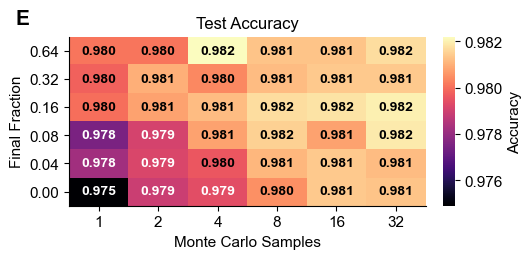

Best accuracy: 0.9822
  mc=4, final_frac=0.64


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

# =============================================================================
# PLOT STYLE
# =============================================================================
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ["Helvetica", "Arial", "DejaVu Sans"],
    'font.size': 11,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'legend.fontsize': 10,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'lines.linewidth': 1.5,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.autolayout': False,
})

def _panel_label(ax, label):
    ax.text(-0.15, 1.05, label, transform=ax.transAxes,
            ha="left", va="bottom", fontsize=15, fontweight="bold")

# Plot heatmap
fig, ax = plt.subplots(figsize=(5.5, 2.75))

im = ax.imshow(accuracy_grid, cmap='magma', aspect='auto', origin='lower')

# Set ticks and labels
ax.set_xticks(range(len(mc_values)))
ax.set_xticklabels(mc_values)
ax.set_yticks(range(len(final_frac_values)))
ax.set_yticklabels([f'{ff:.2f}' for ff in final_frac_values])

ax.set_xlabel('Monte Carlo Samples')
ax.set_ylabel('Final Fraction')
ax.set_title('Test Accuracy', fontsize=12)

# Add colorbar
cbar = plt.colorbar(im, ax=ax,aspect=15, pad=0.04)
cbar.set_label('Accuracy')
cbar.outline.set_visible(False)

# Get the colormap and normalizer
cmap = plt.cm.magma
norm = plt.Normalize(vmin=accuracy_grid.min(), vmax=accuracy_grid.max())

for i in range(len(final_frac_values)):
    for j in range(len(mc_values)):
        # Get the RGBA color for this cell
        rgba = cmap(norm(accuracy_grid[i, j]))
        # Compute perceived luminance (standard formula)
        luminance = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
        color = 'white' if luminance < 0.5 else 'black'
        ax.text(j, i, f'{accuracy_grid[i, j]:.3f}',
                ha='center', va='center', color=color, fontsize=10, fontweight='bold')

_panel_label(ax, "E")
        
plt.tight_layout()

for ext in ['.pdf', '.svg', '.png']:
    plt.savefig(f'accuracy_grid2{ext}', transparent=True, bbox_inches='tight')

plt.show()

# Print best configuration
best_idx = np.unravel_index(np.argmax(accuracy_grid), accuracy_grid.shape)
print(f"\nBest accuracy: {accuracy_grid[best_idx]:.4f}")
print(f"  mc={mc_values[best_idx[1]]}, final_frac={final_frac_values[best_idx[0]]}")

Figure Sx evaluation uses SWA-averaged weights.
Trainable parameters: 203,796
Training epochs: 40
Reusing compatible `accuracy_grid` from the notebook.
Saved FigureSx_MNIST_PST.pdf
Saved FigureSx_MNIST_PST.svg
Saved FigureSx_MNIST_PST.png

FIGURE S2 — MNIST PST
Parameters:       203,796
Epochs:           40
Evaluation:       SWA-averaged weights
Final test:       97.43%
Best averaged:    98.22%
Best MC count:    4
Best final frac.: 0.64


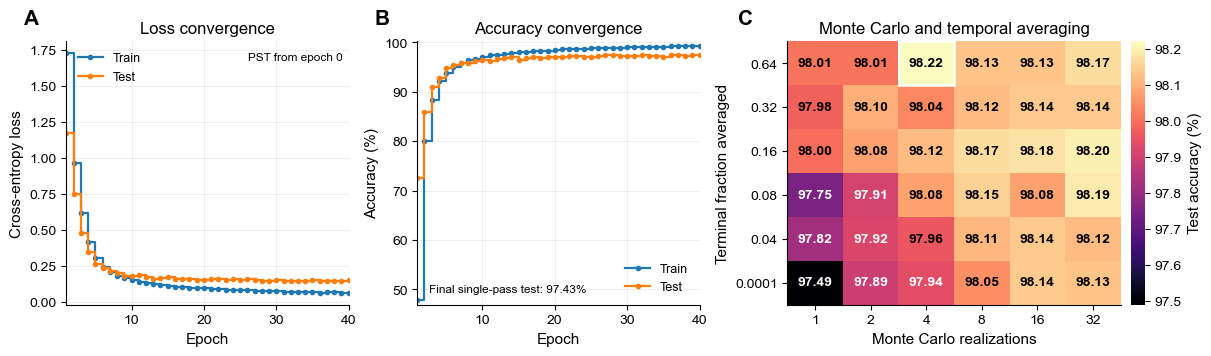

In [ ]:
# =============================================================================
# FIGURE S2: DEEP-LEARNING-SCALE MNIST TRAINING WITH PST
# Training history and Monte Carlo/temporal-averaging evaluation.
#
# Assumes these notebook objects already exist:
#   model, history, config, x_test, y_test,
#   mc_timeavg_accuracy_large_batch, SAVE_DIR, SAVE_PREFIX
# =============================================================================

from pathlib import Path
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# ---------------------------------------------------------------------
# User options
# ---------------------------------------------------------------------
FIGURE_SX_PREFIX = Path("FigureSx_MNIST_PST")
GRID_CACHE = Path(SAVE_DIR) / f"{SAVE_PREFIX}_FigureSx_accuracy_grid.npz"

# The notebook's post-training analysis normally leaves SWA weights active.
USE_AVERAGED_WEIGHTS = True

# Reuse the grid from the preceding notebook cell when compatible.
USE_EXISTING_ACCURACY_GRID = True
RECOMPUTE_ACCURACY_GRID = False

MC_VALUES = np.asarray([1, 2, 4, 8, 16, 32], dtype=np.int32)
FINAL_FRAC_VALUES = np.asarray(
    [1.0e-4, 0.04, 0.08, 0.16, 0.32, 0.64],
    dtype=np.float32,
)

# ---------------------------------------------------------------------
# Validate notebook state
# ---------------------------------------------------------------------
_required = (
    "model",
    "history",
    "config",
    "x_test",
    "y_test",
    "mc_timeavg_accuracy_large_batch",
)
_missing = [name for name in _required if name not in globals()]
if _missing:
    raise RuntimeError(
        "Run the training/loading and analysis cells first. Missing: "
        + ", ".join(_missing)
    )

_history_keys = ("train_loss", "test_loss", "train_acc", "test_acc")
_missing_history = [key for key in _history_keys if key not in history]
if _missing_history:
    raise KeyError("History is missing: " + ", ".join(_missing_history))

n_epochs = len(history["train_loss"])
if not all(len(history[key]) == n_epochs for key in _history_keys):
    raise ValueError("The four plotted history arrays have different lengths.")

# ---------------------------------------------------------------------
# Select evaluation weights explicitly
# ---------------------------------------------------------------------
if USE_AVERAGED_WEIGHTS and model.has_averaged_weights():
    model.use_averaged_weights()
    weight_label = "SWA-averaged weights"
else:
    model.use_original_weights()
    weight_label = "final weights"

model.set_training_phase(use_st=True)
print(f"Figure S2 evaluation uses {weight_label}.")
print(f"Trainable parameters: {model.count_params():,}")
print(f"Training epochs: {n_epochs}")

expected_shape = (len(FINAL_FRAC_VALUES), len(MC_VALUES))


def _compatible_existing_grid():
    if "accuracy_grid" not in globals():
        return None

    candidate = np.asarray(globals()["accuracy_grid"], dtype=float)
    if candidate.shape != expected_shape or not np.all(np.isfinite(candidate)):
        return None

    if "mc_values" in globals():
        if not np.array_equal(
            np.asarray(globals()["mc_values"], dtype=np.int32),
            MC_VALUES,
        ):
            return None

    if "final_frac_values" in globals():
        if not np.allclose(
            np.asarray(globals()["final_frac_values"], dtype=np.float32),
            FINAL_FRAC_VALUES,
        ):
            return None

    return candidate.copy()


def _load_cached_grid():
    if not GRID_CACHE.is_file():
        return None

    with np.load(GRID_CACHE) as saved:
        required = {"accuracy_grid", "mc_values", "final_frac_values"}
        if not required.issubset(saved.files):
            return None

        cached_grid = np.asarray(saved["accuracy_grid"], dtype=float)
        cached_mc = np.asarray(saved["mc_values"], dtype=np.int32)
        cached_ff = np.asarray(saved["final_frac_values"], dtype=np.float32)

    if (
        cached_grid.shape != expected_shape
        or not np.array_equal(cached_mc, MC_VALUES)
        or not np.allclose(cached_ff, FINAL_FRAC_VALUES)
        or not np.all(np.isfinite(cached_grid))
    ):
        return None

    return cached_grid


def _compute_accuracy_grid():
    result = np.empty(expected_shape, dtype=np.float64)
    x_test_tf = tf.convert_to_tensor(x_test, dtype=tf.float32)
    y_test_tf = tf.convert_to_tensor(y_test, dtype=tf.float32)

    for row, final_fraction in enumerate(FINAL_FRAC_VALUES):
        ff_tensor = tf.constant(final_fraction, dtype=tf.float32)

        for column, mc_count in enumerate(MC_VALUES):
            print(
                "Evaluating Figure S2 grid: "
                f"MC={int(mc_count):2d}, "
                f"terminal fraction={float(final_fraction):.4g}"
            )

            accuracy = mc_timeavg_accuracy_large_batch(
                model,
                x_test_tf,
                y_test_tf,
                mc=tf.constant(mc_count, dtype=tf.int32),
                final_frac=ff_tensor,
                average_probabilities=False,
            )
            result[row, column] = float(accuracy.numpy())
            print(f"  accuracy={result[row, column]:.4f}")

    GRID_CACHE.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        GRID_CACHE,
        accuracy_grid=result,
        mc_values=MC_VALUES,
        final_frac_values=FINAL_FRAC_VALUES,
        active_weights=np.asarray(weight_label),
        n_epochs=np.asarray(n_epochs),
    )
    print(f"Saved accuracy-grid cache: {GRID_CACHE.name}")
    return result


figure_accuracy_grid = None

if not RECOMPUTE_ACCURACY_GRID and USE_EXISTING_ACCURACY_GRID:
    figure_accuracy_grid = _compatible_existing_grid()
    if figure_accuracy_grid is not None:
        print("Reusing compatible `accuracy_grid` from the notebook.")

if figure_accuracy_grid is None and not RECOMPUTE_ACCURACY_GRID:
    figure_accuracy_grid = _load_cached_grid()
    if figure_accuracy_grid is not None:
        print(f"Loaded accuracy-grid cache: {GRID_CACHE.name}")

if figure_accuracy_grid is None:
    figure_accuracy_grid = _compute_accuracy_grid()

# ---------------------------------------------------------------------
# Publication style
# ---------------------------------------------------------------------
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
        "font.size": 11,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "legend.fontsize": 9,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "lines.linewidth": 1.6,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "mathtext.fontset": "dejavusans",
    }
)


def _panel_label(ax, label):
    ax.text(
        -0.15,
        1.05,
        label,
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=15,
        fontweight="bold",
    )


epochs = np.arange(1, n_epochs + 1)
train_loss = np.asarray(history["train_loss"], dtype=float)
test_loss = np.asarray(history["test_loss"], dtype=float)
train_acc = np.asarray(history["train_acc"], dtype=float)
test_acc = np.asarray(history["test_acc"], dtype=float)

fig = plt.figure(figsize=(12.0, 3.45), layout="constrained")
grid = fig.add_gridspec(1, 3, width_ratios=(1.0, 1.0, 1.18))

# A: Loss convergence
ax = fig.add_subplot(grid[0, 0])
ax.plot(epochs, train_loss, marker=".", drawstyle="steps-post", label="Train")
ax.plot(epochs, test_loss, marker=".", drawstyle="steps-post", label="Test")
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy loss")
ax.set_title("Loss convergence")
ax.set_xlim(1, n_epochs)
ax.grid(True, alpha=0.2)
ax.legend(frameon=False)
ax.text(
    0.98,
    0.96,
    "PST from epoch 0",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=8.5,
)
_panel_label(ax, "A")

# B: Accuracy convergence
ax = fig.add_subplot(grid[0, 1])
ax.plot(
    epochs,
    100.0 * train_acc,
    marker=".",
    drawstyle="steps-post",
    label="Train",
)
ax.plot(
    epochs,
    100.0 * test_acc,
    marker=".",
    drawstyle="steps-post",
    label="Test",
)
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy (%)")
ax.set_title("Accuracy convergence")
ax.set_xlim(1, n_epochs)
accuracy_min = 100.0 * min(float(np.min(train_acc)), float(np.min(test_acc)))
ax.set_ylim(max(0.0, accuracy_min - 1.0), 100.2)
ax.grid(True, alpha=0.2)
ax.legend(frameon=False, loc="lower right")
ax.text(
    0.04,
    0.04,
    f"Final single-pass test: {100.0 * test_acc[-1]:.2f}%",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=8.5,
)
_panel_label(ax, "B")

# C: Monte Carlo and terminal-time averaging
ax = fig.add_subplot(grid[0, 2])
grid_percent = 100.0 * figure_accuracy_grid
image = ax.imshow(
    grid_percent,
    cmap="magma",
    aspect="auto",
    origin="lower",
    interpolation="nearest",
)
ax.set_xticks(np.arange(len(MC_VALUES)))
ax.set_xticklabels([str(int(value)) for value in MC_VALUES])
ax.set_yticks(np.arange(len(FINAL_FRAC_VALUES)))
ax.set_yticklabels(
    [
        "0.0001" if value < 0.001 else f"{float(value):.2f}"
        for value in FINAL_FRAC_VALUES
    ]
)
ax.set_xlabel("Monte Carlo realizations")
ax.set_ylabel("Terminal fraction averaged")
ax.set_title("Monte Carlo and temporal averaging")

normalizer = plt.Normalize(
    vmin=float(np.nanmin(grid_percent)),
    vmax=float(np.nanmax(grid_percent)),
)
cmap = plt.colormaps["magma"]

for row in range(grid_percent.shape[0]):
    for column in range(grid_percent.shape[1]):
        value = grid_percent[row, column]
        rgba = cmap(normalizer(value))
        luminance = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
        text_color = "white" if luminance < 0.5 else "black"
        ax.text(
            column,
            row,
            f"{value:.2f}",
            ha="center",
            va="center",
            color=text_color,
            fontsize=10,
            fontweight='bold',
        )

best_row, best_column = np.unravel_index(
    np.nanargmax(grid_percent),
    grid_percent.shape,
)
ax.add_patch(
    Rectangle(
        (best_column - 0.5, best_row - 0.5),
        1.0,
        1.0,
        fill=False,
        edgecolor="white",
        linewidth=1.8,
    )
)

colorbar = fig.colorbar(image, ax=ax, aspect=18, pad=0.03)
colorbar.set_label("Test accuracy (%)")
colorbar.outline.set_visible(False)
_panel_label(ax, "C")

# Save PDF/SVG/PNG
for extension in (".pdf", ".svg", ".png"):
    output_path = Path(str(FIGURE_SX_PREFIX) + extension)
    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
        transparent=(extension != ".png"),
    )
    print(f"Saved {output_path.name}")

best_accuracy = grid_percent[best_row, best_column]
best_mc = int(MC_VALUES[best_column])
best_fraction = float(FINAL_FRAC_VALUES[best_row])

print("\n" + "=" * 72)
print("FIGURE S2 — MNIST PST")
print("=" * 72)
print(f"Parameters:       {model.count_params():,}")
print(f"Epochs:           {n_epochs}")
print(f"Evaluation:       {weight_label}")
print(f"Final test:       {100.0 * test_acc[-1]:.2f}%")
print(f"Best averaged:    {best_accuracy:.2f}%")
print(f"Best MC count:    {best_mc}")
print(f"Best final frac.: {best_fraction:.4g}")
print("=" * 72)

plt.show()

